In [2]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
#from utils import *
#from utils_cpdir import *
from utils_mvcp import *
from utils import *
import os

In [3]:
import scipy.sparse as sparse
from scipy.sparse.linalg import spsolve

def baseline_als(y, lam, p, niter=10):
    L = len(y)
    D = sparse.csc_matrix(np.diff(np.eye(L), 2))
    w = np.ones(L)
    for i in range(niter):
        W = sparse.spdiags(w, 0, L, L)
        Z = W + lam * D.dot(D.transpose())
        z = spsolve(Z, w*y)
        w = p * (y > z) + (1-p) * (y < z)
    return z

In [3]:
reference_library = pd.read_excel(open('20240508_AllStandards_AvgNorm_mIRageSpectra_v4.xlsx', 'rb'),
                  sheet_name='LDPE')
reference_library

,OPTIR waveno,OPTIR avg norm,OPTIR norm std error,Unnamed: 3,Raman waveno,Raman avg norm,Raman norm std error,0.2-9.9 um low-density polyethylene iced atomized,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,0.2-9.9 um low-density polyethylene iced atomized.1
0,948,0.019964,0.008088,NaN,326.122151,0.035577,0.009554,Sample obtained on 20230707,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Sample obtained on 20230707
1,950,0.018338,0.008408,NaN,329.593769,0.072053,0.018119,n=25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,952,0.022932,0.007918,NaN,333.065387,0.090134,0.017832,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,954,0.014770,0.005462,NaN,336.537004,0.121637,0.013738,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,956,0.006413,0.004765,NaN,340.008622,0.103368,0.013645,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1023,2994,0.014969,0.009072,NaN,3877.587229,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1024,2996,0.022805,0.012732,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1025,2998,0.003960,0.001598,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1026,3000,0.028148,0.019101,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
df_list_IR = []
df_list_Raman = []
raman_wave_num = None
for s in ['AFR', 'LDPE', 'PSL', 'PP', 'NaNO3', '(NH4)2SO4', 'Sucrose']:
    print(s)
    df = pd.read_excel(open('20240508_AllStandards_AvgNorm_mIRageSpectra_v4.xlsx', 'rb'),
                  sheet_name=s)  
    df_IR = df.loc[:, ['OPTIR waveno', 'OPTIR avg norm']].set_index('OPTIR waveno').T
    df_IR['polymer'] = s
    
    df_Raman = df.loc[:, ['Raman waveno', 'Raman avg norm']]
    if s == 'AFR':
        raman_wave_num = df_Raman['Raman waveno']
        
    df_Raman['Raman waveno'] = raman_wave_num
    df_Raman = df_Raman[~np.isnan(df_Raman['Raman waveno'])].set_index('Raman waveno').T
    df_Raman['polymer'] = s
    
    df_list_IR.append(df_IR)
    df_list_Raman.append(df_Raman)
    

AFR
LDPE
PSL
PP
NaNO3
(NH4)2SO4
Sucrose


In [5]:
reference_library_Raman = pd.concat(df_list_Raman,axis=0).reset_index(drop=True)
label_table = pd.DataFrame({'label':np.arange(7), 'polymer':list(set(reference_library_Raman['polymer']))})
reference_library_Raman = reference_library_Raman.merge(label_table)
reference_library_Raman

,326.122150793817,329.593768660664,333.06538652751,336.537004394357,340.008622261204,343.480240128051,346.951857994897,350.423475861744,353.895093728591,357.366711595437,...,3853.28590351005,3856.7575213769,3860.22913924374,3863.70075711059,3867.17237497744,3870.64399284428,3874.11561071113,3877.58722857798,polymer,label
0,1.000000,1.000000,1.000000,0.886860,0.632134,0.314329,0.288290,0.276282,0.266935,0.261810,...,0.672195,0.671748,0.671729,0.671951,0.671400,0.671480,0.671419,0.671564,AFR,3
1,0.035577,0.072053,0.090134,0.121637,0.103368,0.118574,0.152440,0.202056,0.216870,0.204870,...,0.047775,0.039869,0.040376,0.040210,0.026130,0.013046,0.000145,0.000000,LDPE,2
2,0.028556,0.057310,0.081308,0.090329,0.113806,0.114205,0.117631,0.123749,0.136231,0.171662,...,0.052591,0.046698,0.054335,0.037957,0.033704,0.019401,0.000000,0.000000,PSL,6
3,0.007035,0.015492,0.021300,0.039281,0.052612,0.042450,0.034463,0.037718,0.042577,0.060757,...,0.099949,0.093868,0.074179,0.060716,0.025469,0.000000,0.000000,0.000000,PP,4
4,1.187862,1.188808,1.192062,1.197144,1.199740,1.201156,1.203825,1.208632,1.207370,1.213613,...,0.395744,0.393515,0.393305,0.392189,0.390825,0.391682,0.218743,0.098858,NaNO3,0
5,1.151869,1.154021,1.156846,1.158237,1.160250,1.164317,1.167652,1.171604,1.175996,1.179777,...,0.400635,0.400012,0.399352,0.400010,0.398174,0.387807,0.270481,0.010762,(NH4)2SO4,1
6,1.096948,1.116541,1.124350,1.132092,1.138835,1.149721,1.160756,1.171620,1.181398,1.189294,...,0.381098,0.379650,0.379942,0.378891,0.379193,0.378704,0.272811,0.063571,Sucrose,5


In [85]:
reference_library_Raman#.groupby('polymer').count()

,326.122150793817,329.593768660664,333.06538652751,336.537004394357,340.008622261204,343.480240128051,346.951857994897,350.423475861744,353.895093728591,357.366711595437,...,3853.28590351005,3856.7575213769,3860.22913924374,3863.70075711059,3867.17237497744,3870.64399284428,3874.11561071113,3877.58722857798,polymer,label
0,1.000000,1.000000,1.000000,0.886860,0.632134,0.314329,0.288290,0.276282,0.266935,0.261810,...,0.672195,0.671748,0.671729,0.671951,0.671400,0.671480,0.671419,0.671564,AFR,3
1,0.035577,0.072053,0.090134,0.121637,0.103368,0.118574,0.152440,0.202056,0.216870,0.204870,...,0.047775,0.039869,0.040376,0.040210,0.026130,0.013046,0.000145,0.000000,LDPE,2
2,0.028556,0.057310,0.081308,0.090329,0.113806,0.114205,0.117631,0.123749,0.136231,0.171662,...,0.052591,0.046698,0.054335,0.037957,0.033704,0.019401,0.000000,0.000000,PSL,6
3,0.007035,0.015492,0.021300,0.039281,0.052612,0.042450,0.034463,0.037718,0.042577,0.060757,...,0.099949,0.093868,0.074179,0.060716,0.025469,0.000000,0.000000,0.000000,PP,4
4,1.187862,1.188808,1.192062,1.197144,1.199740,1.201156,1.203825,1.208632,1.207370,1.213613,...,0.395744,0.393515,0.393305,0.392189,0.390825,0.391682,0.218743,0.098858,NaNO3,0
5,1.151869,1.154021,1.156846,1.158237,1.160250,1.164317,1.167652,1.171604,1.175996,1.179777,...,0.400635,0.400012,0.399352,0.400010,0.398174,0.387807,0.270481,0.010762,(NH4)2SO4,1
6,1.096948,1.116541,1.124350,1.132092,1.138835,1.149721,1.160756,1.171620,1.181398,1.189294,...,0.381098,0.379650,0.379942,0.378891,0.379193,0.378704,0.272811,0.063571,Sucrose,5


In [6]:
reference_library_Raman.iloc[:,-2:-1]

,polymer
0,AFR
1,LDPE
2,PSL
3,PP
4,NaNO3
5,(NH4)2SO4
6,Sucrose


In [7]:
reference_library_IR = pd.concat(df_list_IR,axis=0).reset_index(drop=True)
reference_library_IR = reference_library_IR.merge(label_table)

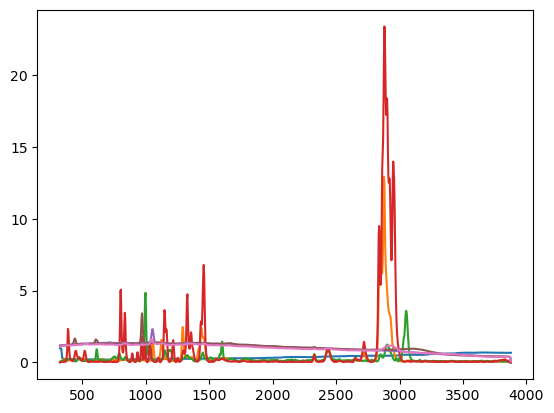

In [8]:
_ = plt.plot(pd.concat(df_list_Raman,axis=0).reset_index(drop=True).iloc[:,:-1].T)

In [9]:
#all([all(df['OPTIR waveno'] == df_list[0]['OPTIR waveno']) for df in df_list])

In [10]:
IR_spectra = pd.read_excel(open('20240326_MixedMPsv7.3_RP_mIRage_allccdata_manualsort.xlsx', 'rb'),
                  sheet_name='PTIR spectra')
IR_spectra.columns = ['wavenumber'] + list(range(1, 676))
IR_spectra = IR_spectra.set_index('wavenumber').T

Raman_spectra = pd.read_excel(open('20240326_MixedMPsv7.3_RP_mIRage_allccdata_manualsort.xlsx', 'rb'),
                  sheet_name='Raman spectra')
Raman_spectra.columns = ['wavenumber'] + list(range(1, 676))
Raman_spectra = Raman_spectra.set_index('wavenumber').T

In [11]:
(IR_spectra.iloc[:,457:875].columns.min(),
IR_spectra.iloc[:,457:875].columns.max())

(1862, 2696)

In [12]:
(IR_spectra.columns.min(),
IR_spectra.columns.max())

(948, 3002)

In [13]:
IR_spectra.iloc[:,list(range(457)) + list(range(875, 1028))]

wavenumber,948,950,952,954,956,958,960,962,964,966,...,2984,2986,2988,2990,2992,2994,2996,2998,3000,3002
1,0.715333,-0.796451,-0.242472,-0.223528,0.469898,-0.854349,-0.696183,-0.040006,-0.007353,0.587008,...,-1.153124,0.323851,0.520567,1.474805,2.696880,-0.933596,-1.981116,-4.203133,1.617839,-2.045081
2,0.212056,0.631615,0.563838,-0.662932,-0.868097,-0.258387,0.462888,0.137573,-0.227954,-0.112606,...,-0.141965,0.434427,1.507167,0.959519,0.416842,2.594737,3.435453,7.815598,5.074497,0.018592
3,1.021753,-0.127142,1.253587,1.281074,0.356386,0.700090,0.893120,1.464102,0.912785,1.240300,...,1.632875,2.600832,4.071292,1.263540,0.039930,0.476370,2.262114,2.345831,0.041729,-0.591140
4,-2.809015,-1.161700,-0.103105,-0.696837,-0.460958,-0.163590,-0.108635,0.048189,-0.262481,0.126052,...,5.379118,5.666609,4.379854,3.489550,2.045514,3.839099,5.089821,4.200088,1.962945,-1.957872
5,0.907647,1.582182,0.226826,0.964313,2.846518,3.215438,2.578081,3.015029,3.710880,3.420349,...,10.252533,9.568037,9.559546,9.897161,9.784099,8.416503,6.132834,6.585536,2.560741,0.113437
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
671,-1.778515,-1.162944,-1.692678,-0.126718,-1.090406,0.389977,-0.595141,-0.657634,-0.683976,-0.247207,...,-0.112262,-1.044709,2.181222,1.218790,1.878411,1.427564,-2.123268,-0.380655,0.280983,-4.309794
672,-3.298637,0.224048,-2.582387,-3.262183,-0.436456,-0.060726,-0.767382,-0.349041,-0.415763,-0.529353,...,-2.468078,2.251735,-0.045148,-0.466533,-0.678616,-0.458567,0.303920,1.875410,1.371869,-3.305835
673,3.772151,3.079321,3.447310,4.966950,2.004281,1.034197,0.367880,0.104764,1.157395,0.823033,...,1.252109,1.863259,1.734788,3.073306,4.713561,2.296088,0.915084,7.199690,6.321640,-1.361913
674,2.048347,-2.725135,2.430814,3.246009,1.830246,0.829516,0.198038,0.840114,0.182406,1.104591,...,0.698777,-1.288116,0.803734,4.261713,4.722067,2.899487,3.839103,4.058119,6.611619,6.414655


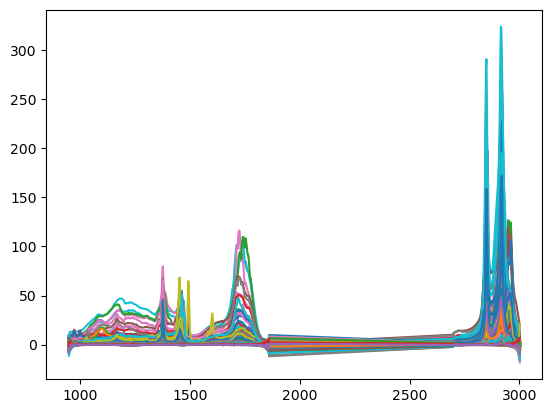

In [14]:
_ = plt.plot(IR_spectra.iloc[:,list(range(457)) + list(range(875, 1028))].T)

In [15]:
sum((np.array(IR_spectra.columns) - np.array(reference_library_IR.columns[:-2])) ** 2)


0

In [16]:
labels = pd.read_excel(open('20240326_MixedMPsv7.3_RP_mIRage_allccdata_manualsort.xlsx', 'rb'),
                  sheet_name='Other cc data and sort').loc[:,['Overall ID', 'Manual overall']]
labels.columns = ['id', 'polymer']
pol_list = ["PSL","PP","LDPE"]
labels = labels.query('polymer in @pol_list')
labels = labels.merge(label_table)
labels = labels.sort_values(by='id')
labels.to_csv('/Users/eochoa/Documents/conformal-hqi/rebecca_data_labels.csv')

In [17]:
Raman_spectra.loc[labels['id'],:]

wavenumber,326.122151,329.593769,333.065387,336.537004,340.008622,343.480240,346.951858,350.423476,353.895094,357.366712,...,3846.342668,3849.814286,3853.285904,3856.757521,3860.229139,3863.700757,3867.172375,3870.643993,3874.115611,3877.587229
1,8860.0,8687.957031,8793.525391,8828.403320,8717.911133,8774.787109,8861.554688,8960.846680,9057.664062,9133.549805,...,4214.559082,4169.086426,4209.511719,4165.931152,4209.408203,4189.356445,4186.843262,4265.183105,4198.424805,4274.0
2,12572.0,12453.622070,12389.363281,12368.252930,12389.205078,12471.358398,12492.412109,12557.039062,12612.623047,12657.501953,...,5529.690430,5463.541992,5567.219238,5502.442383,5381.349609,5368.081543,5355.459961,5429.685547,5491.009277,5480.0
4,7984.0,7939.805176,7910.516113,7910.766602,7944.572754,8004.608398,8128.855469,8063.730469,7981.246094,8021.808594,...,5715.352051,5760.326660,5666.683105,5719.488770,5649.394531,5641.479004,5645.303711,5760.113770,5687.101562,5748.0
5,17206.0,17087.621094,16991.892578,17075.919922,17327.402344,17496.449219,17583.585938,17498.363281,17411.246094,17442.171875,...,12879.750000,12963.892578,12836.389648,12773.843750,12821.677734,12756.069336,12627.841797,12824.100586,12902.442383,12900.0
6,7424.0,7417.686523,7468.451172,7555.564941,7630.721191,7595.963379,7617.872559,7753.738281,7827.015625,7757.832520,...,4696.145020,4589.410156,4579.121582,4568.143066,4571.723145,4531.808594,4602.695312,4509.408691,4501.778809,4578.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
658,8728.0,8718.529297,8703.178711,8735.304688,8828.153320,8943.484375,8958.952148,8843.922852,8819.271484,8996.541016,...,5913.544922,5845.934082,5955.609375,5818.511230,5826.643555,5909.780273,5744.768066,5805.823730,5804.959961,5862.0
661,7750.0,7734.216309,7676.383301,7716.102539,7819.530762,7693.140137,7760.602051,7923.398926,8027.470215,8017.019043,...,6795.617676,6732.172852,6893.218262,6710.921875,6722.314941,6654.370605,6813.766602,6872.667480,6821.858398,6770.0
668,8138.0,8139.578613,8089.879883,8094.553223,8143.471680,8054.998047,8175.331543,8208.338867,8254.816406,8372.846680,...,7690.337891,7627.303223,7635.414551,7590.336426,7621.685059,7491.754883,7551.920898,7635.622559,7584.990723,7780.0
670,5048.0,5041.686523,4893.136719,4759.462402,4721.925781,4769.322266,4876.443359,4935.615234,4930.242676,4899.301270,...,3938.543457,3845.215332,3879.512207,3903.258301,3870.854736,3767.274658,3880.692139,3891.069092,3857.778564,3804.0


In [18]:
reference_library_Raman

,326.122150793817,329.593768660664,333.06538652751,336.537004394357,340.008622261204,343.480240128051,346.951857994897,350.423475861744,353.895093728591,357.366711595437,...,3853.28590351005,3856.7575213769,3860.22913924374,3863.70075711059,3867.17237497744,3870.64399284428,3874.11561071113,3877.58722857798,polymer,label
0,1.000000,1.000000,1.000000,0.886860,0.632134,0.314329,0.288290,0.276282,0.266935,0.261810,...,0.672195,0.671748,0.671729,0.671951,0.671400,0.671480,0.671419,0.671564,AFR,3
1,0.035577,0.072053,0.090134,0.121637,0.103368,0.118574,0.152440,0.202056,0.216870,0.204870,...,0.047775,0.039869,0.040376,0.040210,0.026130,0.013046,0.000145,0.000000,LDPE,2
2,0.028556,0.057310,0.081308,0.090329,0.113806,0.114205,0.117631,0.123749,0.136231,0.171662,...,0.052591,0.046698,0.054335,0.037957,0.033704,0.019401,0.000000,0.000000,PSL,6
3,0.007035,0.015492,0.021300,0.039281,0.052612,0.042450,0.034463,0.037718,0.042577,0.060757,...,0.099949,0.093868,0.074179,0.060716,0.025469,0.000000,0.000000,0.000000,PP,4
4,1.187862,1.188808,1.192062,1.197144,1.199740,1.201156,1.203825,1.208632,1.207370,1.213613,...,0.395744,0.393515,0.393305,0.392189,0.390825,0.391682,0.218743,0.098858,NaNO3,0
5,1.151869,1.154021,1.156846,1.158237,1.160250,1.164317,1.167652,1.171604,1.175996,1.179777,...,0.400635,0.400012,0.399352,0.400010,0.398174,0.387807,0.270481,0.010762,(NH4)2SO4,1
6,1.096948,1.116541,1.124350,1.132092,1.138835,1.149721,1.160756,1.171620,1.181398,1.189294,...,0.381098,0.379650,0.379942,0.378891,0.379193,0.378704,0.272811,0.063571,Sucrose,5


In [19]:
IR_spectra.to_csv('/Users/eochoa/Documents/conformal-hqi/rebecca_data_ir.csv')

In [80]:
IR_spectra

wavenumber,948,950,952,954,956,958,960,962,964,966,...,2984,2986,2988,2990,2992,2994,2996,2998,3000,3002
1,0.715333,-0.796451,-0.242472,-0.223528,0.469898,-0.854349,-0.696183,-0.040006,-0.007353,0.587008,...,-1.153124,0.323851,0.520567,1.474805,2.696880,-0.933596,-1.981116,-4.203133,1.617839,-2.045081
2,0.212056,0.631615,0.563838,-0.662932,-0.868097,-0.258387,0.462888,0.137573,-0.227954,-0.112606,...,-0.141965,0.434427,1.507167,0.959519,0.416842,2.594737,3.435453,7.815598,5.074497,0.018592
3,1.021753,-0.127142,1.253587,1.281074,0.356386,0.700090,0.893120,1.464102,0.912785,1.240300,...,1.632875,2.600832,4.071292,1.263540,0.039930,0.476370,2.262114,2.345831,0.041729,-0.591140
4,-2.809015,-1.161700,-0.103105,-0.696837,-0.460958,-0.163590,-0.108635,0.048189,-0.262481,0.126052,...,5.379118,5.666609,4.379854,3.489550,2.045514,3.839099,5.089821,4.200088,1.962945,-1.957872
5,0.907647,1.582182,0.226826,0.964313,2.846518,3.215438,2.578081,3.015029,3.710880,3.420349,...,10.252533,9.568037,9.559546,9.897161,9.784099,8.416503,6.132834,6.585536,2.560741,0.113437
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
671,-1.778515,-1.162944,-1.692678,-0.126718,-1.090406,0.389977,-0.595141,-0.657634,-0.683976,-0.247207,...,-0.112262,-1.044709,2.181222,1.218790,1.878411,1.427564,-2.123268,-0.380655,0.280983,-4.309794
672,-3.298637,0.224048,-2.582387,-3.262183,-0.436456,-0.060726,-0.767382,-0.349041,-0.415763,-0.529353,...,-2.468078,2.251735,-0.045148,-0.466533,-0.678616,-0.458567,0.303920,1.875410,1.371869,-3.305835
673,3.772151,3.079321,3.447310,4.966950,2.004281,1.034197,0.367880,0.104764,1.157395,0.823033,...,1.252109,1.863259,1.734788,3.073306,4.713561,2.296088,0.915084,7.199690,6.321640,-1.361913
674,2.048347,-2.725135,2.430814,3.246009,1.830246,0.829516,0.198038,0.840114,0.182406,1.104591,...,0.698777,-1.288116,0.803734,4.261713,4.722067,2.899487,3.839103,4.058119,6.611619,6.414655


In [20]:
labels

,id,polymer,label
0,1,PSL,6
86,2,PP,4
182,4,LDPE,2
87,5,PP,4
88,6,PP,4
...,...,...,...
180,658,PP,4
304,661,LDPE,2
305,668,LDPE,2
181,670,PP,4


In [21]:
Raman_spectra

wavenumber,326.122151,329.593769,333.065387,336.537004,340.008622,343.480240,346.951858,350.423476,353.895094,357.366712,...,3846.342668,3849.814286,3853.285904,3856.757521,3860.229139,3863.700757,3867.172375,3870.643993,3874.115611,3877.587229
1,8860.0,8687.957031,8793.525391,8828.403320,8717.911133,8774.787109,8861.554688,8960.846680,9057.664062,9133.549805,...,4214.559082,4169.086426,4209.511719,4165.931152,4209.408203,4189.356445,4186.843262,4265.183105,4198.424805,4274.0
2,12572.0,12453.622070,12389.363281,12368.252930,12389.205078,12471.358398,12492.412109,12557.039062,12612.623047,12657.501953,...,5529.690430,5463.541992,5567.219238,5502.442383,5381.349609,5368.081543,5355.459961,5429.685547,5491.009277,5480.0
3,15170.0,15023.210938,15062.093750,15196.102539,15329.639648,15347.018555,15513.617188,15508.814453,15529.968750,15678.732422,...,15467.042969,15414.955078,15358.000000,15396.161133,15695.937500,15718.289062,15670.075195,15836.288086,15960.504883,15910.0
4,7984.0,7939.805176,7910.516113,7910.766602,7944.572754,8004.608398,8128.855469,8063.730469,7981.246094,8021.808594,...,5715.352051,5760.326660,5666.683105,5719.488770,5649.394531,5641.479004,5645.303711,5760.113770,5687.101562,5748.0
5,17206.0,17087.621094,16991.892578,17075.919922,17327.402344,17496.449219,17583.585938,17498.363281,17411.246094,17442.171875,...,12879.750000,12963.892578,12836.389648,12773.843750,12821.677734,12756.069336,12627.841797,12824.100586,12902.442383,12900.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
671,3442.0,3386.756836,3423.285400,3496.798340,3551.051758,3517.874268,3559.269287,3523.548828,3501.794434,3564.765381,...,3064.780518,3057.478760,3154.829102,3152.638428,3160.610840,3262.656494,3193.540527,3089.937500,3089.292236,3125.0
672,5880.0,5969.967773,5940.383301,5930.537598,5967.081543,5914.945312,6062.696289,6121.514160,6175.551758,6265.914062,...,4585.295410,4589.805176,4492.926758,4485.184082,4499.325195,4515.205566,4505.076660,4526.377441,4509.637207,4422.0
673,2994.0,2975.059570,2959.509766,2985.043457,3042.316162,3053.375244,3191.268066,3166.080322,3174.006348,3308.899658,...,2895.263672,2871.042480,2963.560059,2840.940430,2846.629639,2830.945068,2885.077637,2840.176270,2858.615234,2988.0
674,3608.0,3628.518799,3678.291992,3679.960449,3632.316162,3643.375244,3663.396484,3737.625977,3843.551514,3934.167480,...,3283.617676,3199.563721,3195.219238,3168.604004,3204.906494,3153.315430,3169.847900,3142.024658,3174.818604,3144.0


In [22]:
labels.groupby('polymer').count()

,id,label
polymer,,
LDPE,125,125
PP,96,96
PSL,86,86


In [25]:
# store labels/polymer for reference library
y_train = reference_library_Raman.iloc[:,-2].to_numpy()
label_train_Raman = reference_library_Raman.iloc[:,-1].to_numpy()
# store spectra for reference library
X_train_Raman = reference_library_Raman.iloc[:,:-2].to_numpy()

#X_train_Raman = np.diff(X_train_Raman, 1)
# Perform SNV normalization
X_train_Raman = (X_train_Raman - X_train_Raman.mean(1)[:, None]) / X_train_Raman.std(1)[:, None]
#X_train_Raman = X_train_Raman[:, :800]

# store labels/polymer for reference library
y = labels.iloc[:,1].to_numpy()
label_Raman = labels.iloc[:,2].to_numpy()

X_Raman = Raman_spectra.loc[labels['id'],:].to_numpy()

#X_Raman = np.diff(X_Raman, 1)
X_Raman = (X_Raman - X_Raman.mean(1)[:, None]) / X_Raman.std(1)[:, None]

X_Raman_corrected = np.array([x - baseline_als(x, lam=1, p=0, niter=15) for x in X_Raman])

X_Raman_corrected = (X_Raman_corrected - X_Raman_corrected.mean(1)[:, None]) / X_Raman_corrected.std(1)[:, None]

X_Raman_corrected_2 = np.array([x - baseline_als(x, lam=1, p=0, niter=14) for x in X_Raman_corrected])

#X_Raman_corrected_2 = np.diff(X_Raman_corrected_2, 1)
X_Raman_corrected_2 = (X_Raman_corrected_2 - X_Raman_corrected_2.mean(1)[:, None]) / X_Raman_corrected_2.std(1)[:, None]
#X_Raman_corrected_2 = X_Raman_corrected_2[:, :800]


In [24]:
# store labels/polymer for reference library
y_train = reference_library_IR.iloc[:,-2].to_numpy()
label_train_IR = reference_library_IR.iloc[:,-1].to_numpy()
# store spectra for reference library
X_train_IR = reference_library_IR.iloc[:,:-2].to_numpy()

# Perform SNV normalization
X_train_IR = (X_train_IR - X_train_IR.mean(1)[:, None]) / X_train_IR.std(1)[:, None]

# store labels/polymer for reference library
y = labels.iloc[:,1].to_numpy()
label_ = labels.iloc[:,2].to_numpy()

X_IR = IR_spectra.loc[labels['id'],:].to_numpy()
X_IR = (X_IR - X_IR.mean(1)[:, None]) / X_IR.std(1)[:, None]
#X_IR = (X_IR - np.quantile(X_IR, .5,axis=1)[:, None]) /(np.quantile(X_IR, .75,axis=1) - np.quantile(X_IR, .25,axis=1))[:, None]


In [84]:
from sklearn.cluster import KMeans

#X_IR = (X_IR - X_IR.mean(0)) / X_IR.std(0)
kmeans = KMeans(n_clusters=3, random_state=0, ).fit(X_IR)
print(kmeans.labels_)
y_hat_ir_clus = kmeans.predict(X_IR)
y_hat_ir_clus

[1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 2 0 1 1 1 1 1 1 0 1 1 1 0 1 2 1 0 2 0 0 2
 0 1 1 0 2 2 0 0 1 0 2 2 2 1 0 2 1 1 2 1 1 1 1 1 0 1 0 1 0 1 0 1 2 0 1 1 1
 2 1 0 0 0 1 0 0 0 0 2 1 2 1 1 1 1 1 2 2 2 1 1 1 0 2 2 1 0 1 0 1 0 1 1 2 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 0 1 1 1 1 0 1 1 1 1 1 2 0 0 1 1 2 0 1 1 0 1
 1 2 1 2 0 2 2 0 0 0 1 1 2 1 0 1 1 1 0 1 0 1 1 0 1 0 1 0 0 1 2 1 1 1 1 0 1
 1 0 0 1 2 1 0 1 1 1 0 0 1 0 1 1 1 2 0 1 1 1 2 2 1 1 1 1 0 1 0 0 1 1 1 0 2
 0 1 1 0 1 1 1 1 1 1 1 1 0 1 1 0 2 1 1 1 1 1 1 1 1 1 1 0 1 1 0 1 1 1 1 1 0
 1 1 1 2 0 2 0 1 2 2 1 0 1 1 1 0 1 1 0 2 0 2 1 0 1 1 0 0 2 0 1 1 2 0 1 0 2
 0 1 1 0 1 2 1 0 1 1 2]


array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 2, 0, 1, 1, 1, 1,
       1, 1, 0, 1, 1, 1, 0, 1, 2, 1, 0, 2, 0, 0, 2, 0, 1, 1, 0, 2, 2, 0,
       0, 1, 0, 2, 2, 2, 1, 0, 2, 1, 1, 2, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0,
       1, 0, 1, 2, 0, 1, 1, 1, 2, 1, 0, 0, 0, 1, 0, 0, 0, 0, 2, 1, 2, 1,
       1, 1, 1, 1, 2, 2, 2, 1, 1, 1, 0, 2, 2, 1, 0, 1, 0, 1, 0, 1, 1, 2,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0,
       1, 1, 1, 1, 1, 2, 0, 0, 1, 1, 2, 0, 1, 1, 0, 1, 1, 2, 1, 2, 0, 2,
       2, 0, 0, 0, 1, 1, 2, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0,
       0, 1, 2, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 2, 1, 0, 1, 1, 1, 0, 0, 1,
       0, 1, 1, 1, 2, 0, 1, 1, 1, 2, 2, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1,
       0, 2, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 2, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 2, 0,
       2, 0, 1, 2, 2, 1, 0, 1, 1, 1, 0, 1, 1, 0, 2, 0, 2, 1, 0, 1, 1, 0,
       0, 2, 0, 1, 1, 2, 0, 1, 0, 2, 0, 1, 1, 0, 1,

In [85]:
pd.DataFrame({'label_hat':y_hat_ir_clus,'label':label_, 'n':1}).groupby(['label','label_hat']).count()

n
label label_hat    
0     0          40
      1          20
      2          26
3     0          27
      1          88
      2          10
6     0          14
      1          72
      2          10

In [86]:
pd.DataFrame({'label_hat':y_hat_ir_clus,'label':label_, 'n':1}).groupby(['label','label_hat']).count()

n
label label_hat    
0     0          40
      1          20
      2          26
3     0          27
      1          88
      2          10
6     0          14
      1          72
      2          10

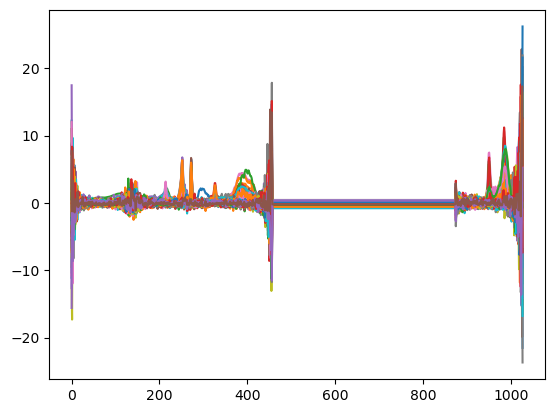

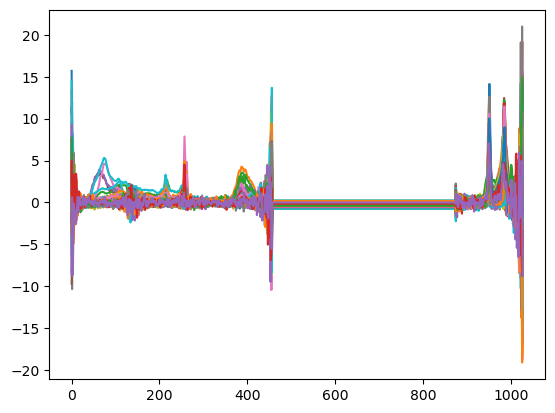

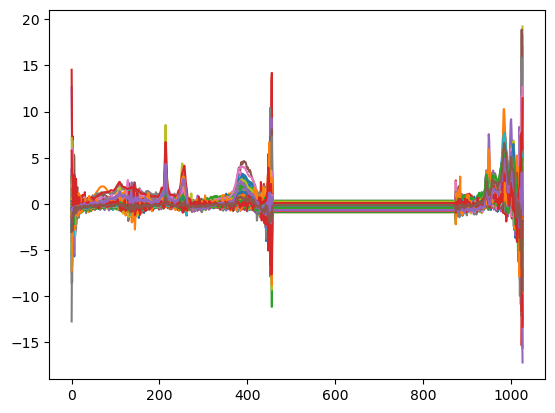

In [87]:
for i in np.unique(label_):
    _ = plt.plot(X_IR[label_ == i,:].T)
    _ = plt.show()


In [88]:
np.corrcoef(X_IR)

array([[1.        , 0.55784424, 0.42906437, ..., 0.42557218, 0.7029224 ,
        0.34169773],
       [0.55784424, 1.        , 0.44801293, ..., 0.36125042, 0.75896421,
        0.3110128 ],
       [0.42906437, 0.44801293, 1.        , ..., 0.46917537, 0.43353009,
        0.47542984],
       ...,
       [0.42557218, 0.36125042, 0.46917537, ..., 1.        , 0.52890268,
        0.27349189],
       [0.7029224 , 0.75896421, 0.43353009, ..., 0.52890268, 1.        ,
        0.38490871],
       [0.34169773, 0.3110128 , 0.47542984, ..., 0.27349189, 0.38490871,
        1.        ]])

1


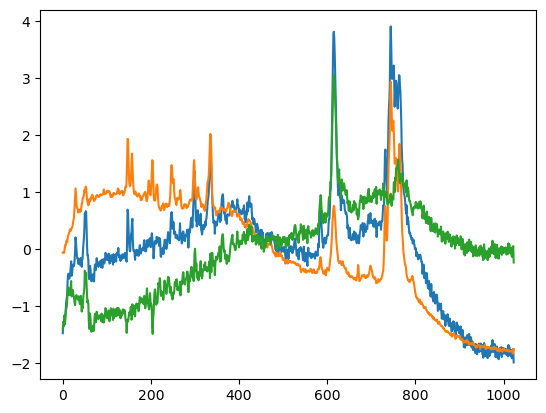

2


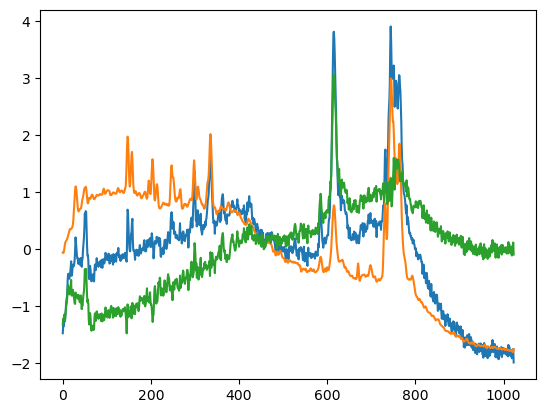

3


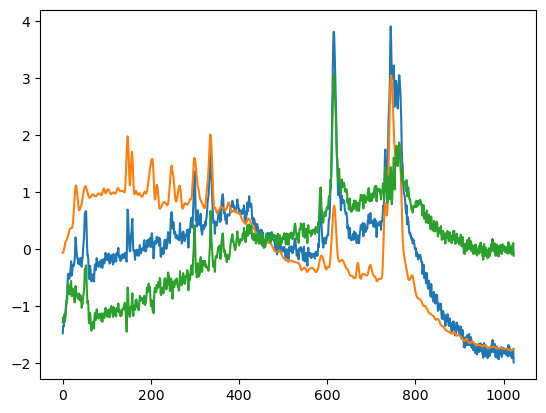

4


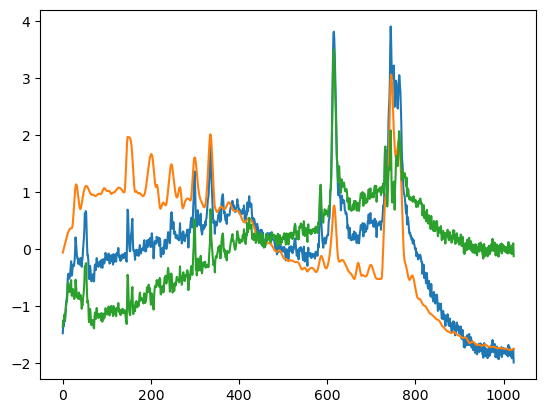

5


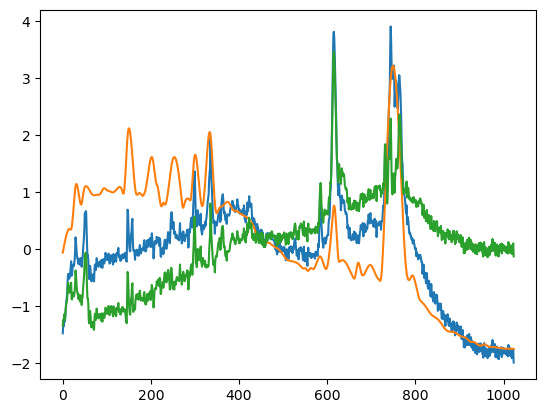

6


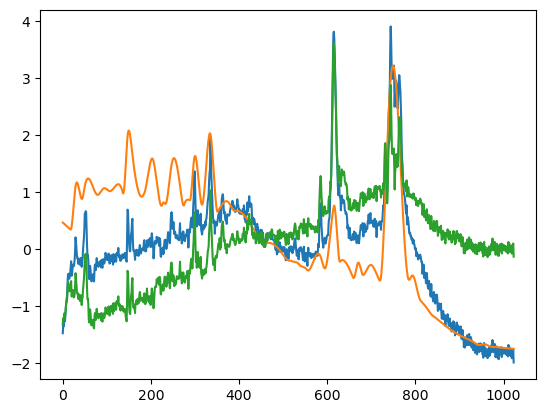

7


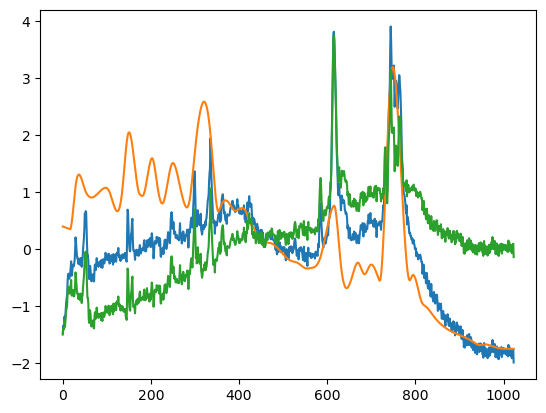

8


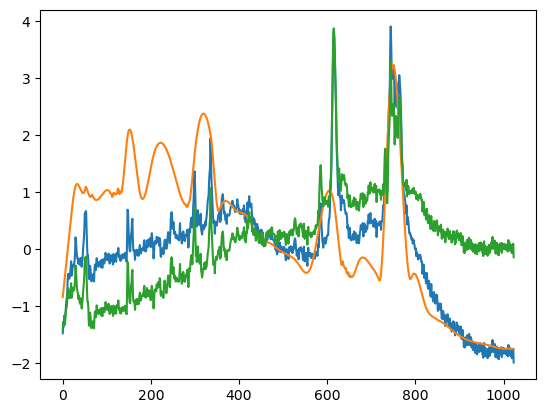

9


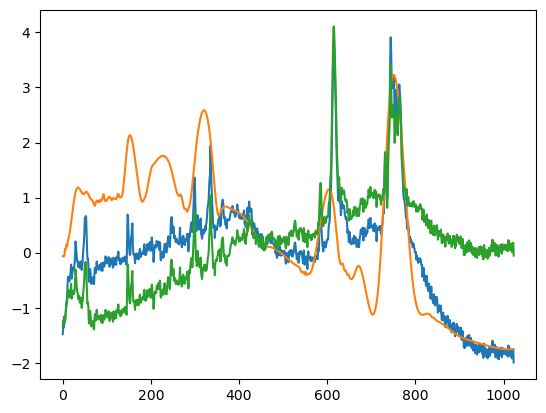

10


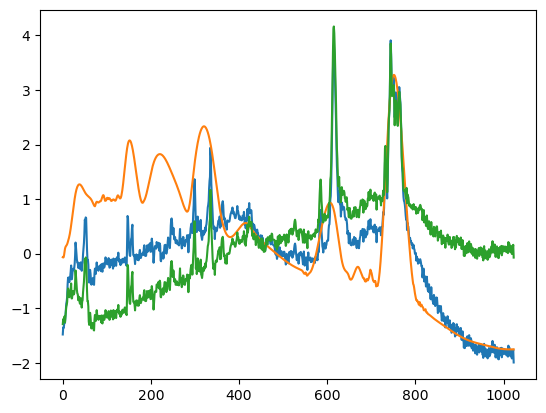

11


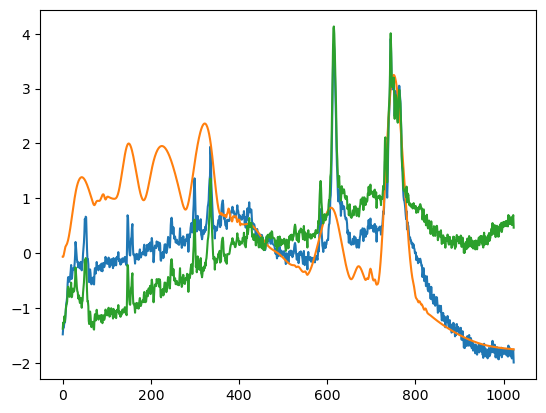

12


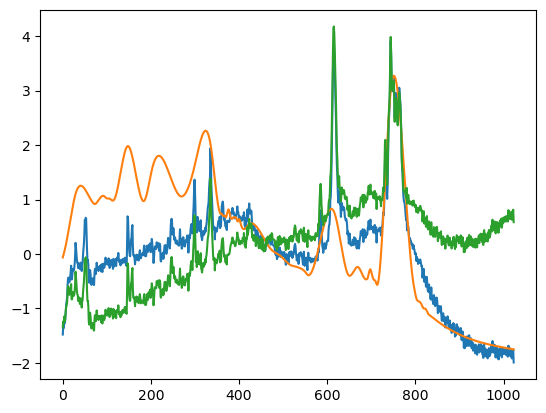

13


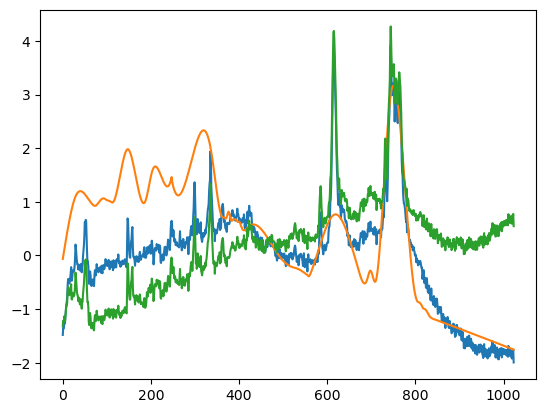

14


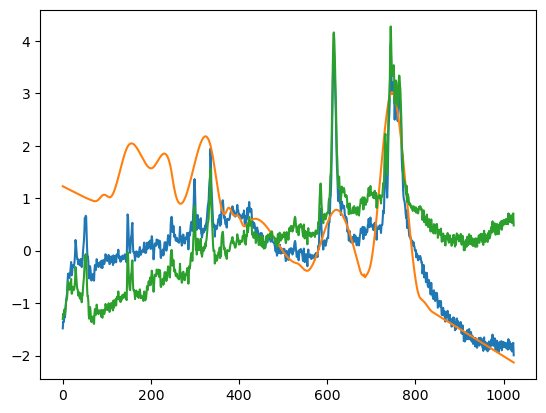

15


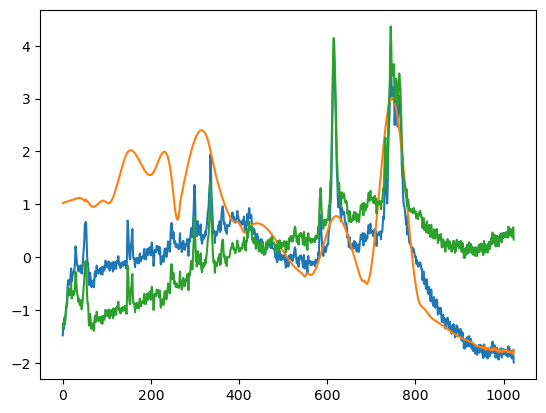

16


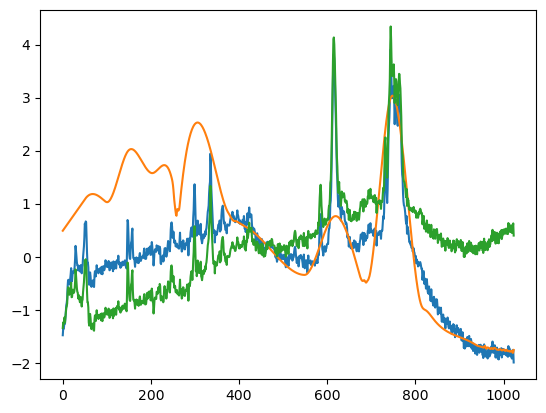

17


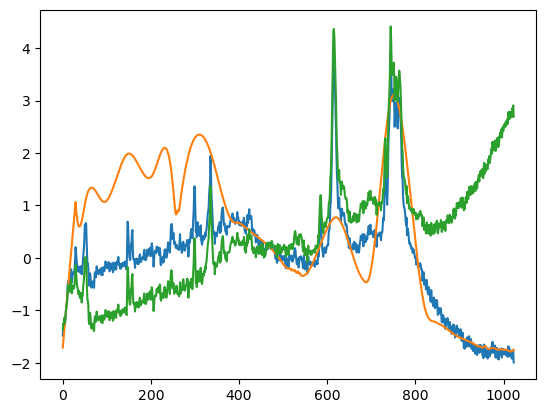

18


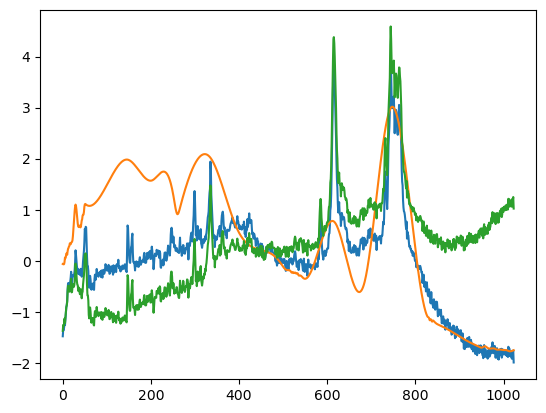

19


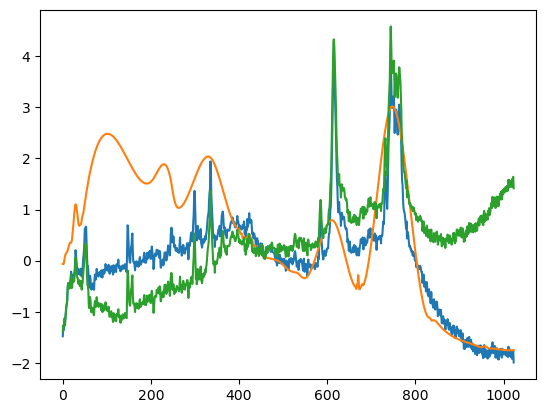

20


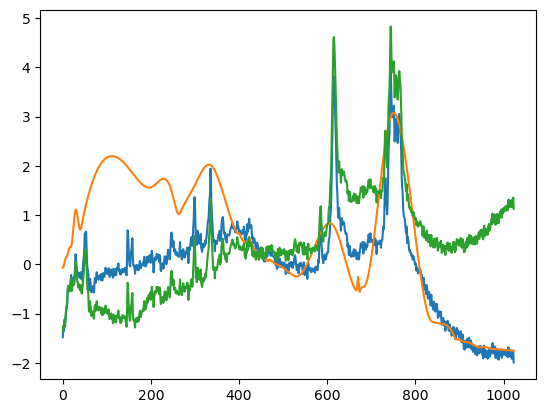

21


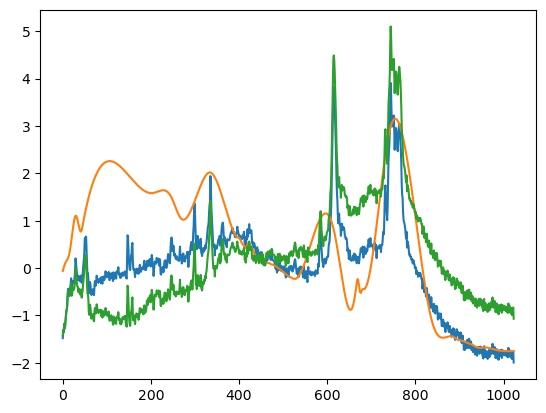

22


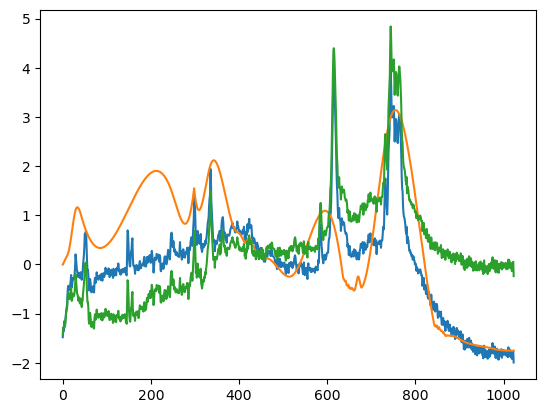

23


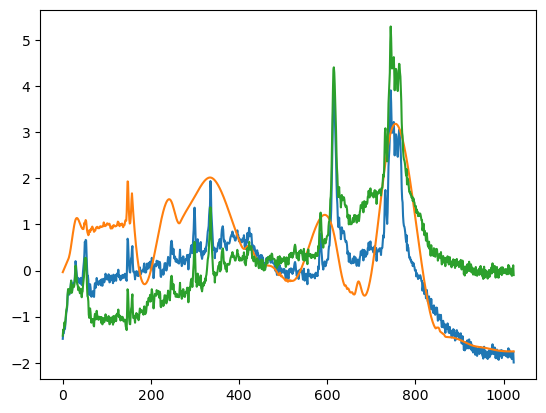

24


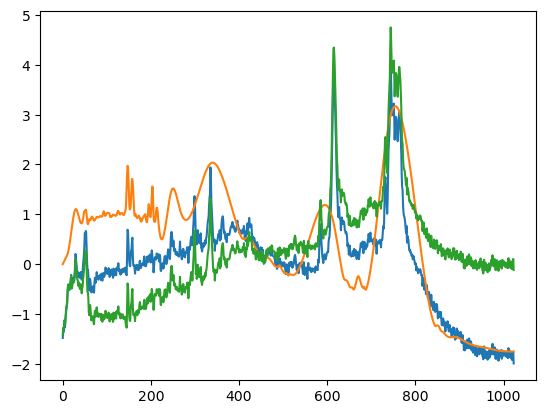

25


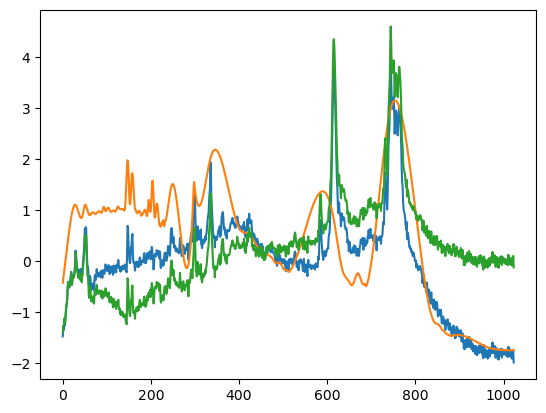

26


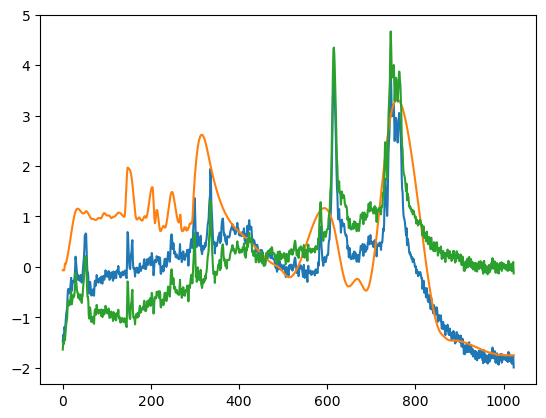

27


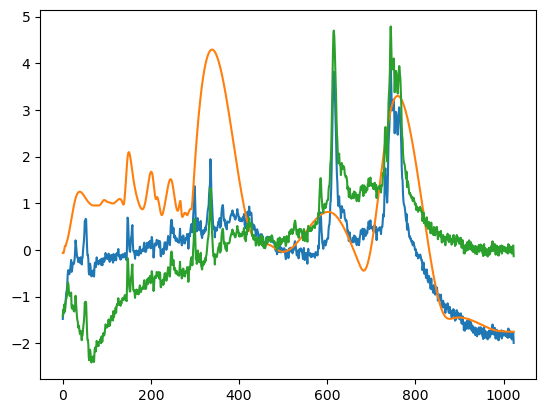

28


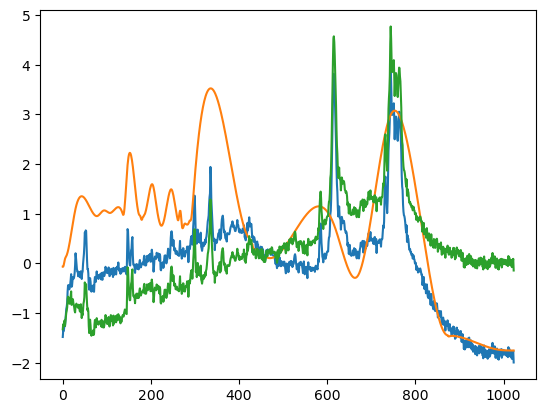

29


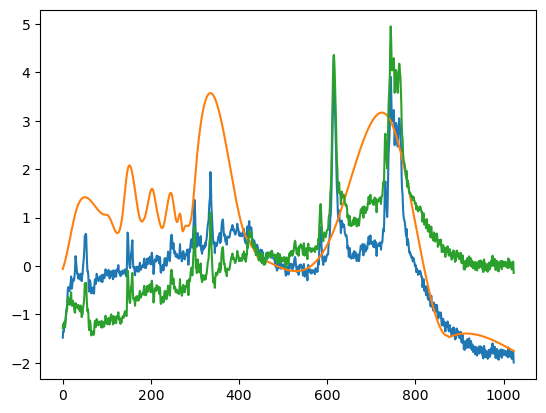

In [89]:
for j in range(1,30):
    print(j)
    plt.plot(X_Raman[y == 'PP'][14,:])
    plt.plot(baseline_als(X_Raman[y == 'PP'][i,:], lam=.1, p=1, niter=j))
    plt.plot(X_Raman[y == 'PP'][14,:]-baseline_als(X_Raman[y == 'PP'][i,:], lam=.1, p=0, niter=j))
    plt.show()

0.01


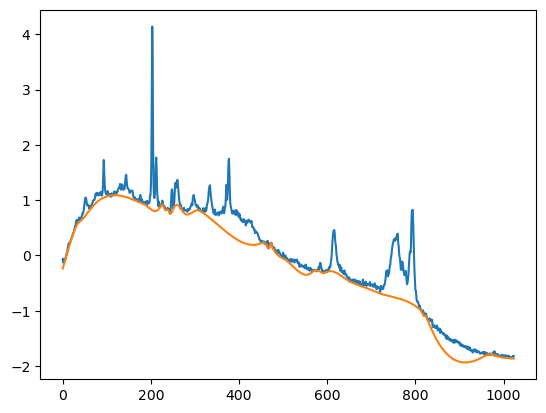

0.06210526315789474


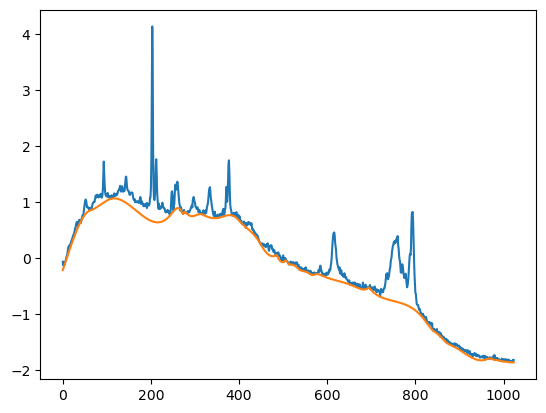

0.11421052631578947


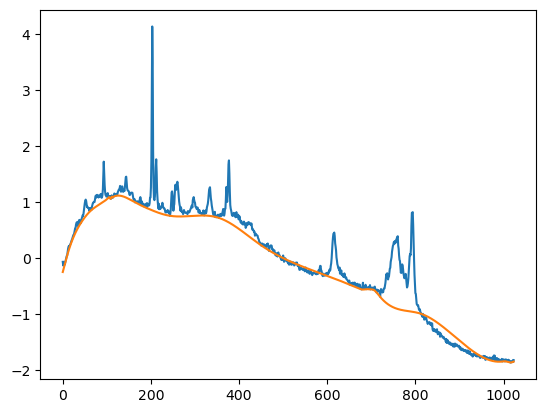

0.16631578947368422


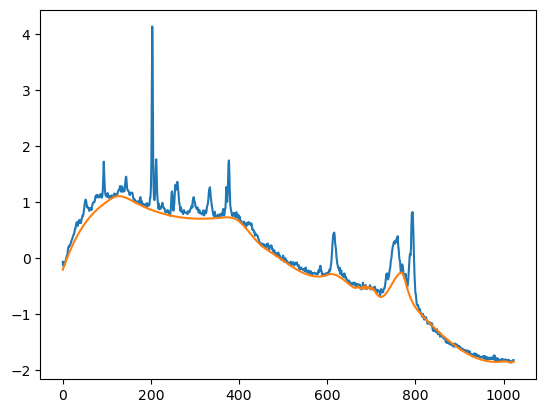

0.21842105263157896


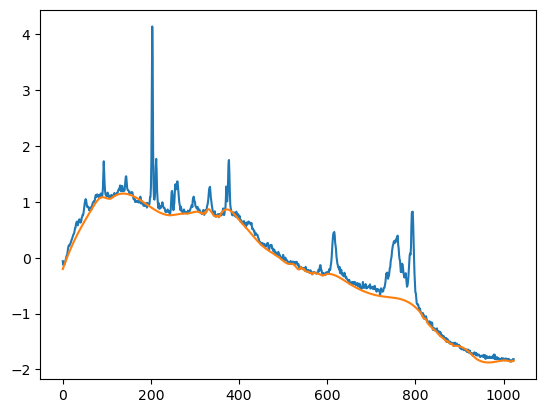

0.2705263157894737


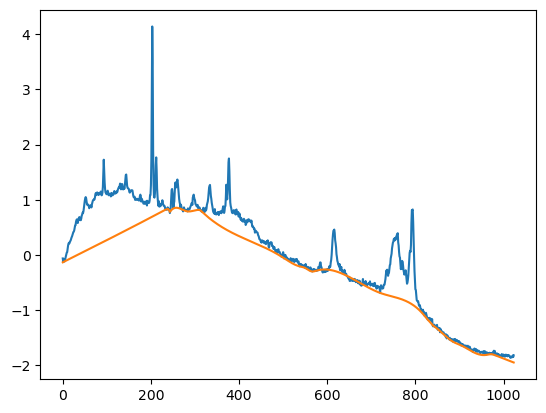

0.32263157894736844


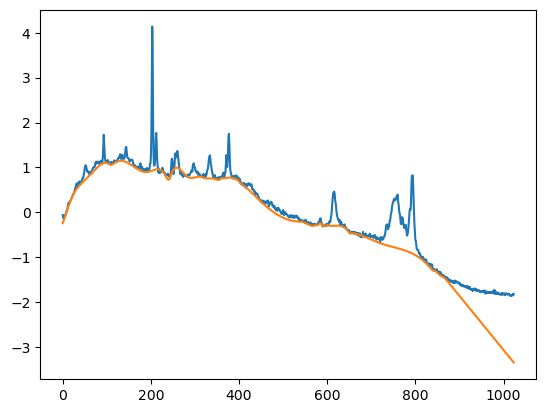

0.37473684210526315


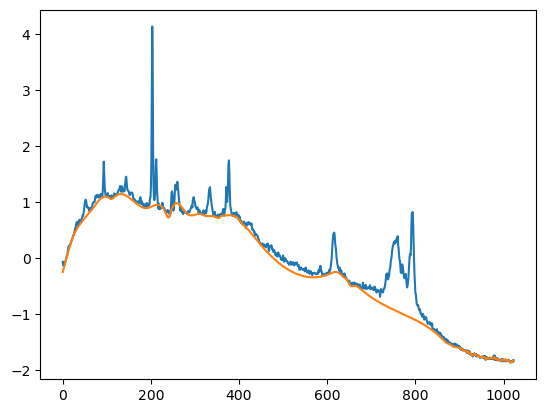

0.4268421052631579


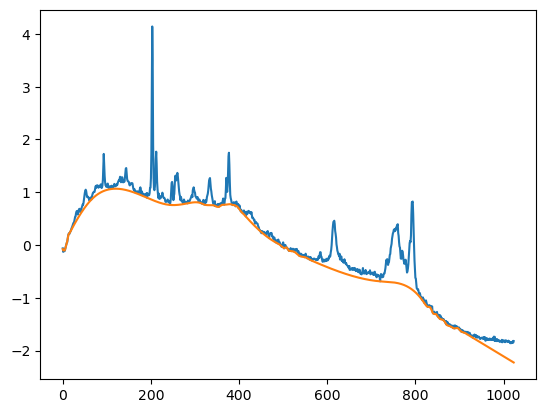

0.4789473684210527


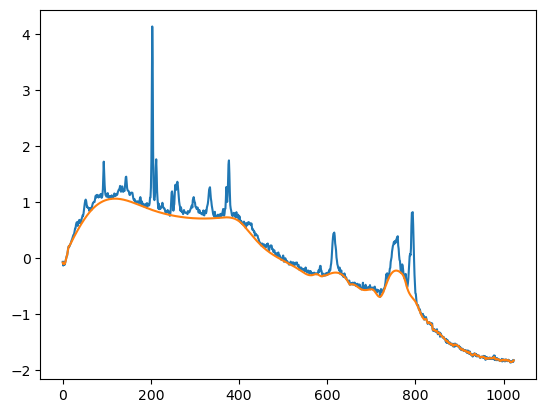

0.5310526315789474


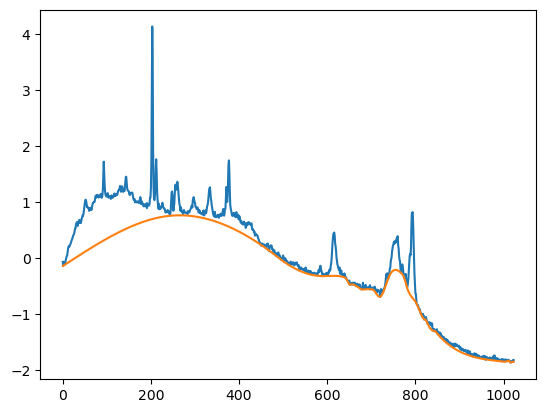

0.5831578947368421


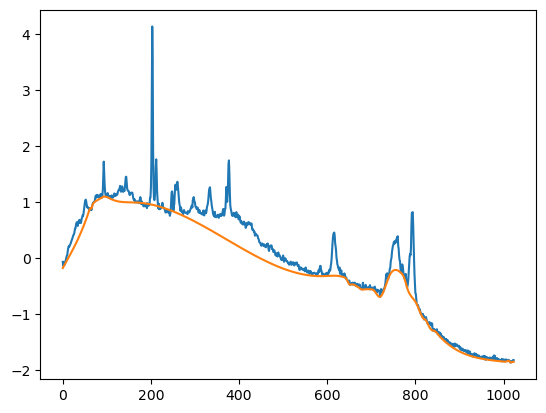

0.6352631578947369


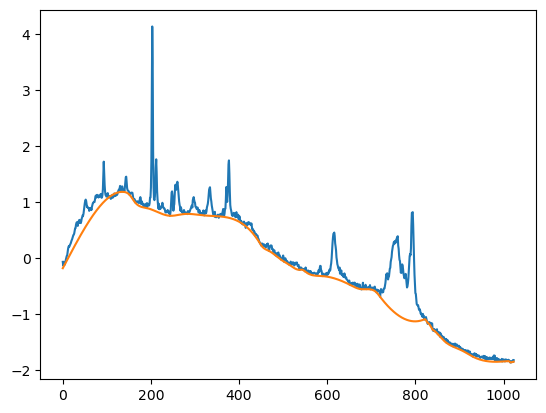

0.6873684210526316


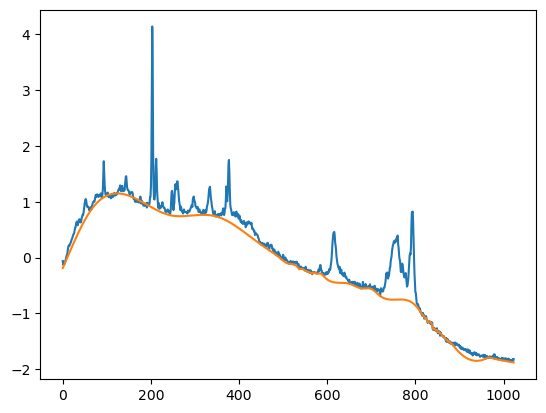

0.7394736842105263


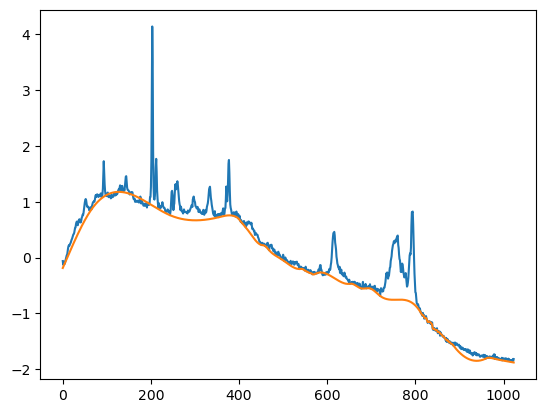

0.791578947368421


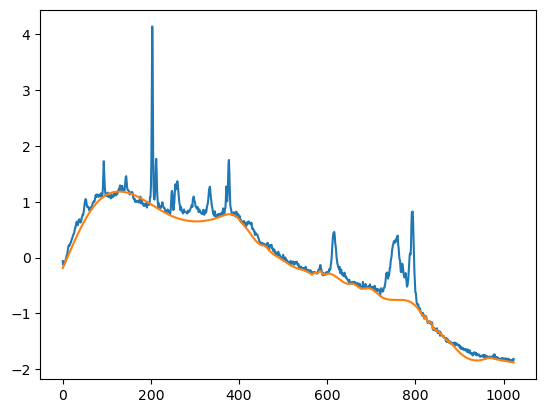

0.8436842105263158


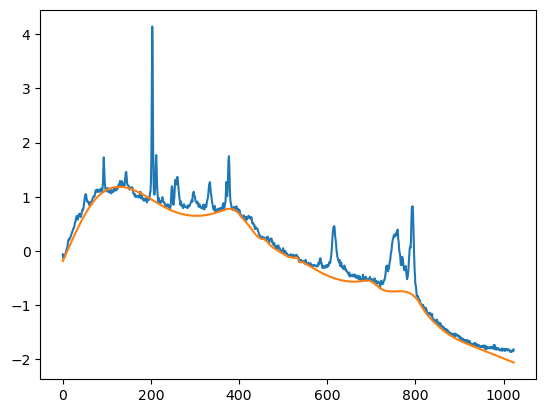

0.8957894736842106


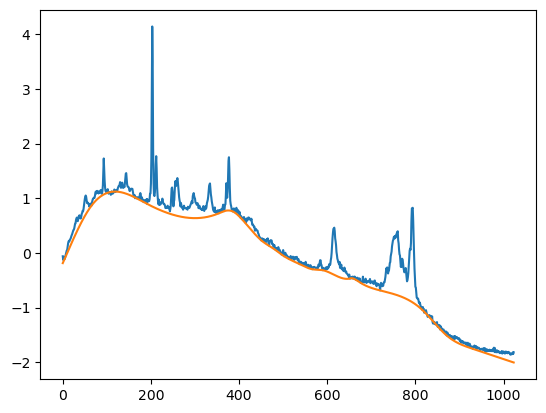

0.9478947368421053


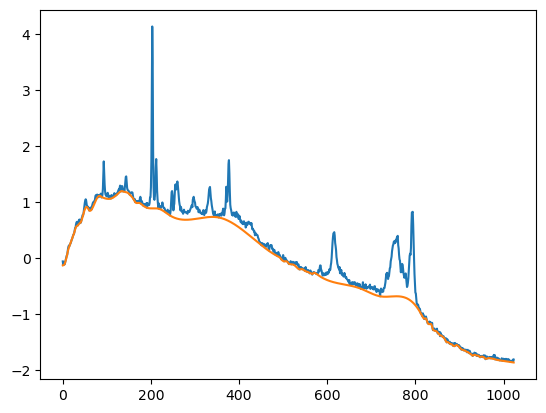

1.0


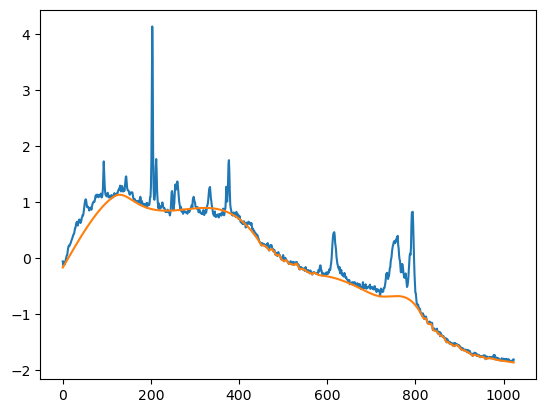

In [90]:
for j in np.linspace(0.01,1,20):
    print(j)
    plt.plot(X_Raman[0])
    plt.plot(baseline_als(X_Raman[0], lam=j, p=0, niter=15))
    plt.show()

14


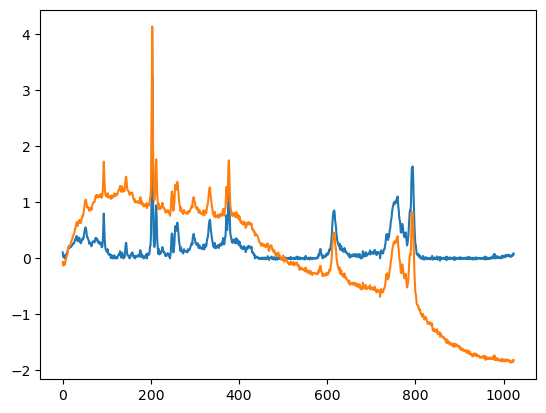

In [91]:
for j in [14]:
    print(j)
    plt.plot(X_Raman[0] - baseline_als(X_Raman[0], lam=1, p=0, niter=j))
    plt.plot(X_Raman[0])
    plt.show()

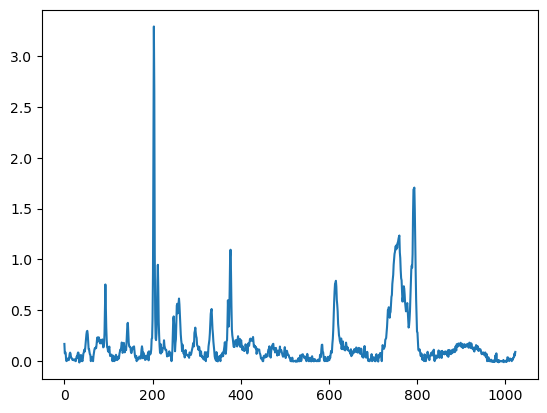

In [92]:
plt.plot(X_Raman[0] - baseline_als(X_Raman[0], lam=.1, p=0, niter=14))

In [93]:
reference_library_Raman.columns[:-2][:800]

Index([326.122150793817, 329.593768660664,  333.06538652751, 336.537004394357,
       340.008622261204, 343.480240128051, 346.951857994897, 350.423475861744,
       353.895093728591, 357.366711595437,
       ...
        3068.7002656027, 3072.17188346954, 3075.64350133639, 3079.11511920324,
       3082.58673707008, 3086.05835493693, 3089.52997280378, 3093.00159067062,
       3096.47320853747, 3099.94482640432],
      dtype='object', length=800)

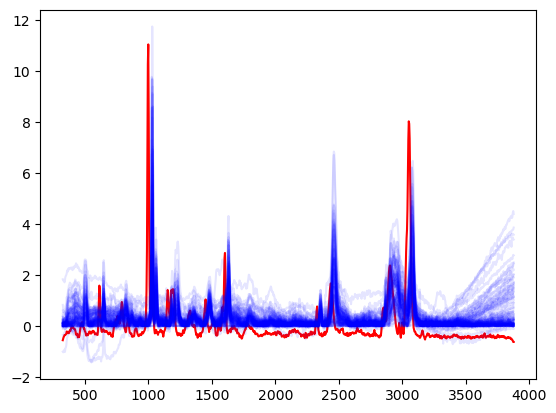

In [94]:
X_Raman_corrected = np.array([x - baseline_als(x, lam=1, p=0, niter=14) for x in X_Raman])
_ = plt.plot(reference_library_Raman.columns[:-2], X_train_Raman[y_train == 'PSL',:].T, c='r')
_ = plt.plot(reference_library_Raman.columns[:-2], X_Raman_corrected[y == 'PSL',:].T, c='b', alpha=.1)

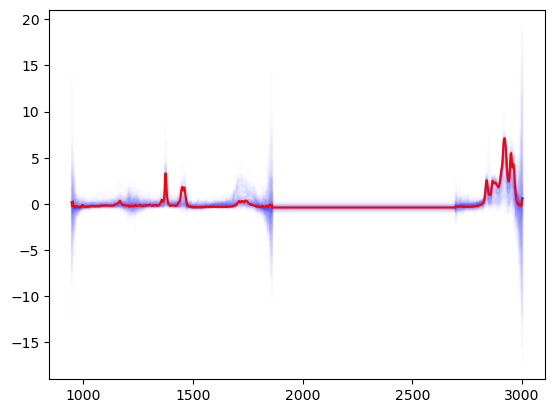

In [95]:
X_IR_corrected = np.array([x - baseline_als(x, lam=1, p=0, niter=14) for x in X_IR])
_ = plt.plot(reference_library_IR.columns[:-2], X_IR[y == 'PP',:].T, c='b', alpha=.01)
_ = plt.plot(reference_library_IR.columns[:-2], X_train_IR[y_train == 'PP',:].T, c='r')

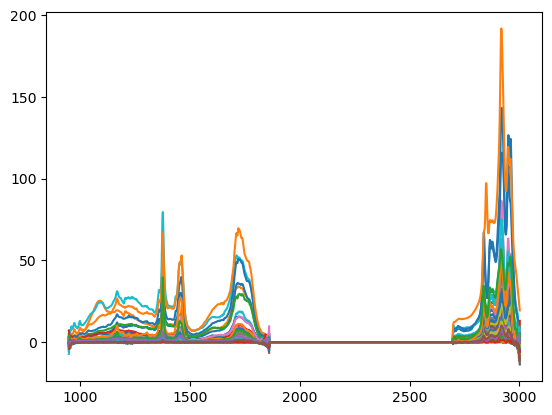

In [96]:
#X_IR = IR_spectra.loc[labels['id'],:].to_numpy()
#_ = plt.plot(reference_library_IR.columns[:-2], X_IR[y == 'PP',:].T)

In [75]:
X_Raman_corrected_2 = np.array([x - baseline_als(x, lam=.1, p=0, niter=14) for x in X_Raman_corrected])
X_Raman_corrected_2 = (X_Raman_corrected_2 - X_Raman_corrected_2.mean(1)[:, None]) / X_Raman_corrected_2.std(1)[:, None]


In [98]:
np.unique(y)

array(['LDPE', 'PP', 'PSL'], dtype=object)

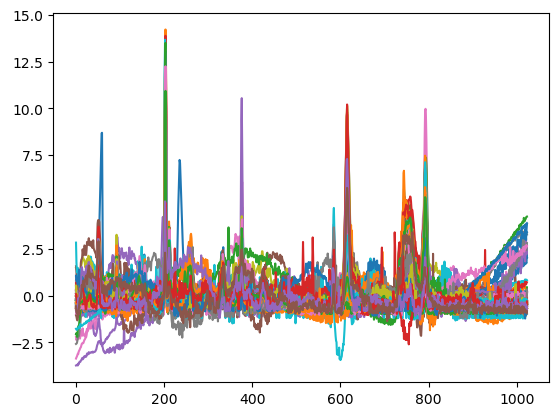

In [76]:
_ = plt.plot(X_Raman_corrected_2[y == 'PSL'].T)

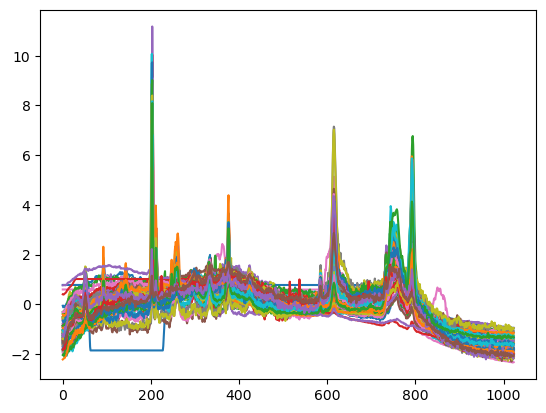

In [100]:
_ = plt.plot(X_Raman[y == 'PSL'].T)

In [101]:
X_Raman_corrected[y == 'PP'].mean(1)

array([ 0.14249902,  0.37232045,  0.28855281,  0.23447271,  0.30647265,
        0.28528191,  0.24340727,  0.10838007,  0.21184935,  0.21124881,
        0.30367475,  0.01895822,  0.36880932,  0.36167863,  0.39121669,
        0.29566978,  0.25312746,  0.16774207,  0.37060029,  0.43826263,
        0.38455688,  0.30511578,  0.42935788,  0.32053882,  0.46513787,
        0.31811375,  0.27146575,  0.82985043,  0.148709  ,  0.33677659,
        0.29798013,  0.21279676,  0.2927849 ,  0.26493793,  0.43333913,
        0.41748062,  0.28059645,  0.29993422,  0.40557079,  0.24525434,
        0.26854815,  0.21031769,  0.19501727,  0.22662111,  0.3485635 ,
        0.32240791,  0.26014371,  0.44712561,  0.3342488 ,  0.25816305,
        0.23477702,  0.39717527,  0.15053818,  0.58401948,  0.31971999,
        0.34803653,  0.30666746,  0.24613476,  0.06556707,  0.2045885 ,
        0.20872779,  0.200314  ,  0.44983147,  0.34957776,  0.15039642,
        0.43891798,  0.35337982, -0.19916558,  0.32942463,  0.23

0


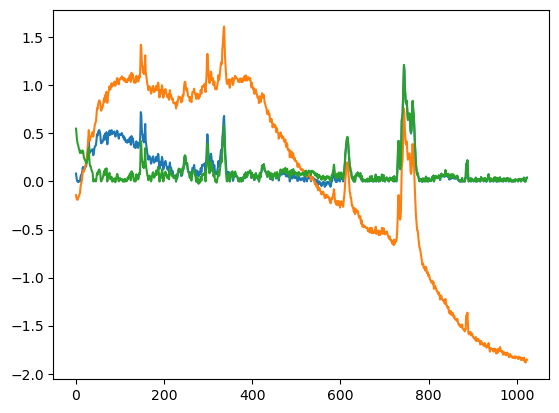

1


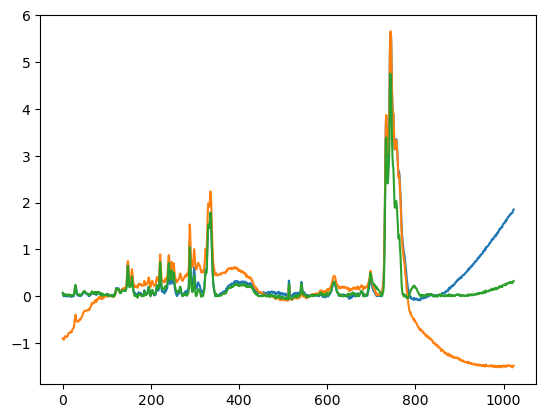

2


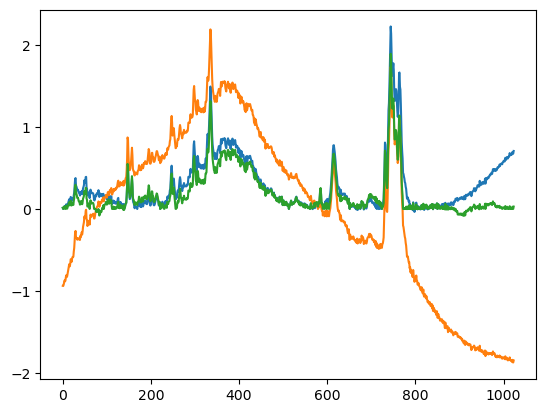

3


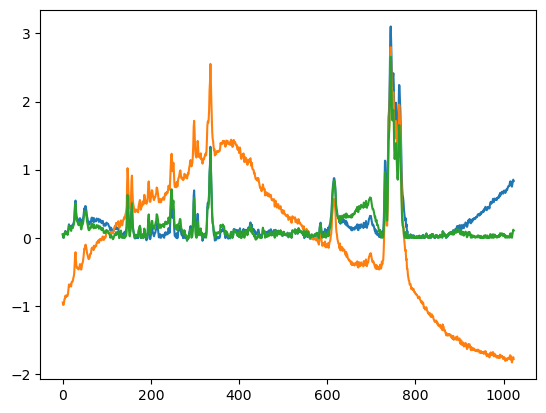

4


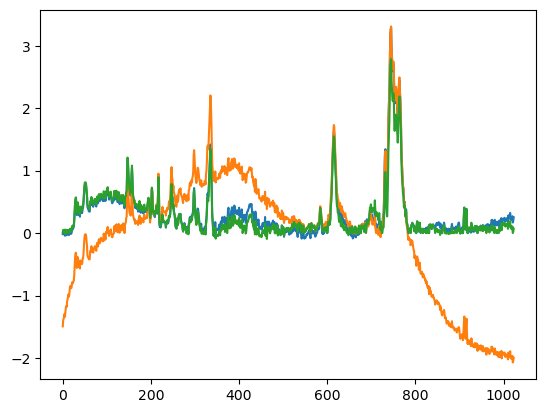

5


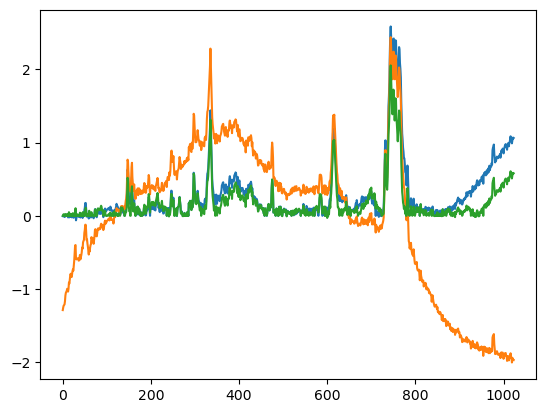

6


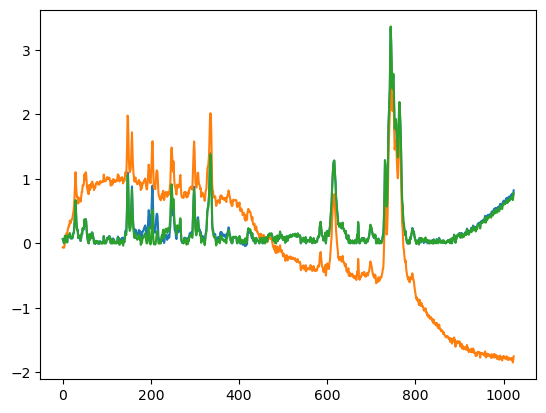

7


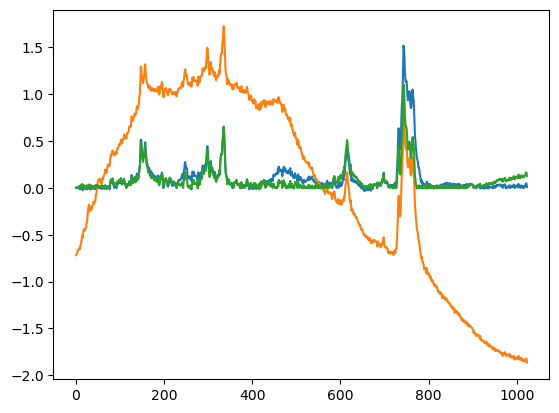

8


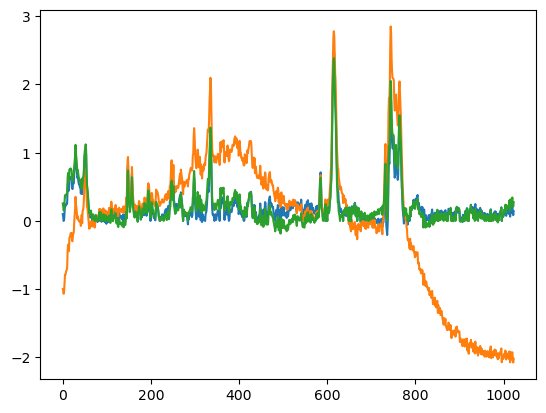

9


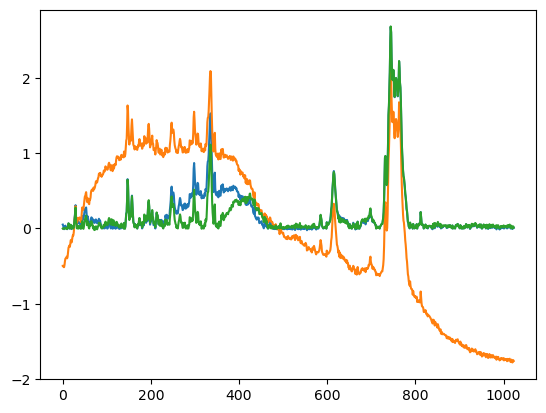

10


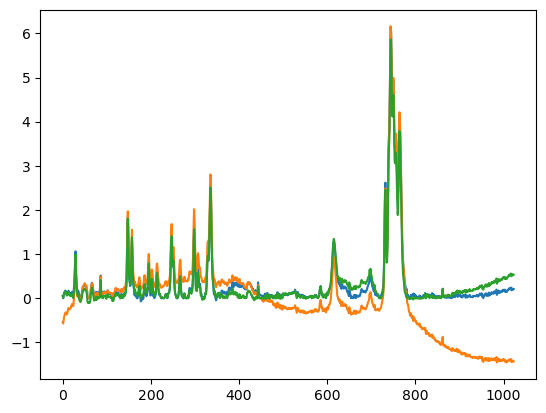

11


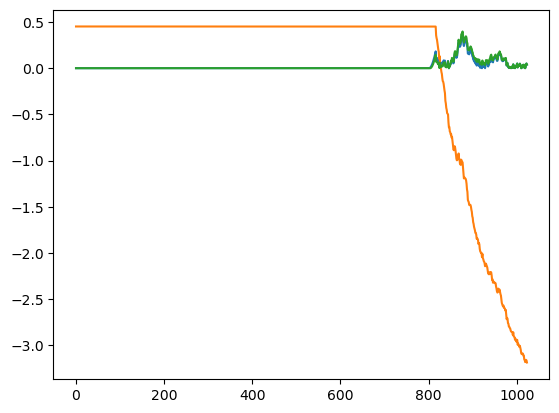

12


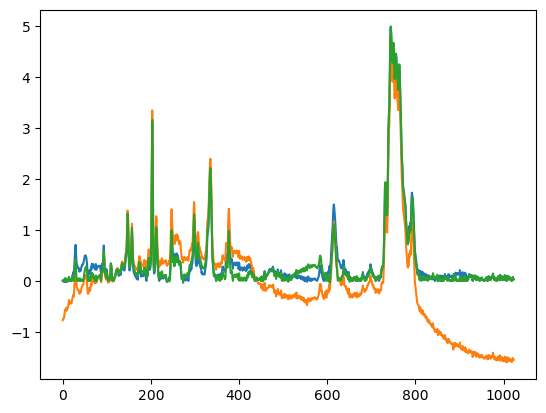

13


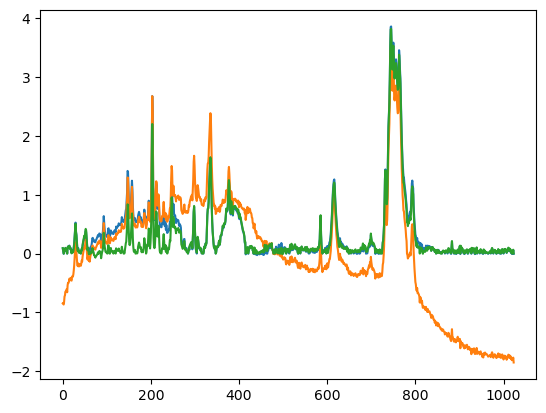

14


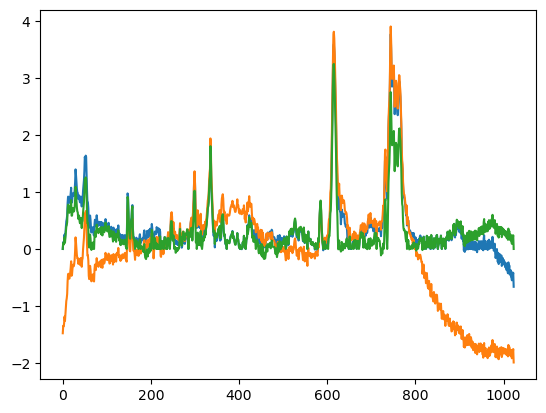

15


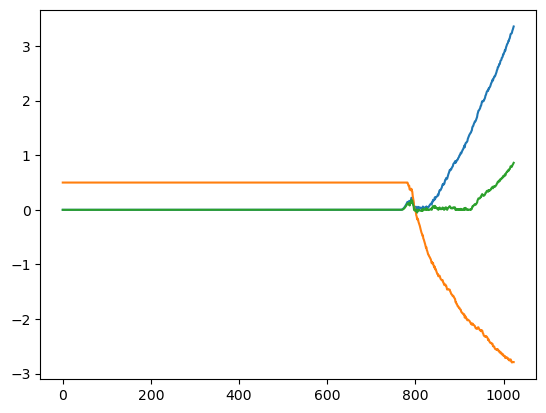

16


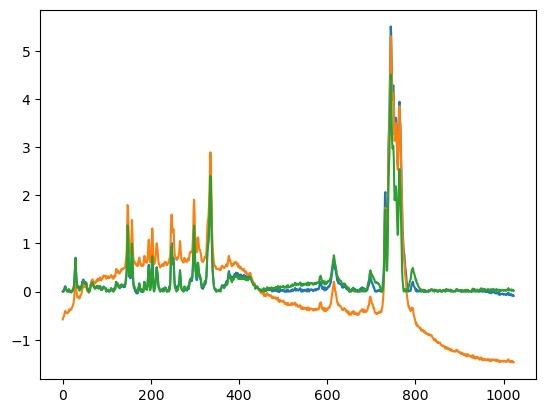

17


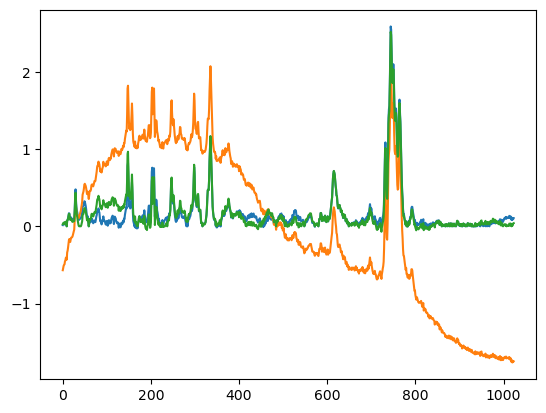

18


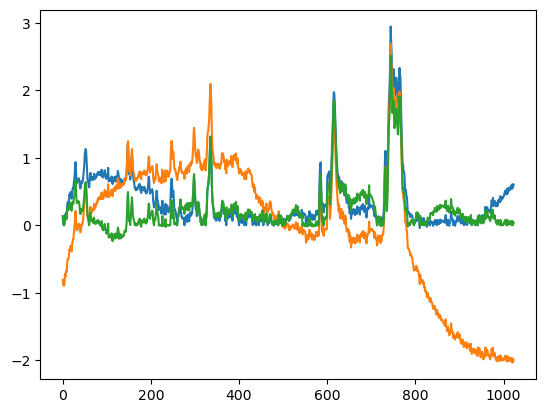

19


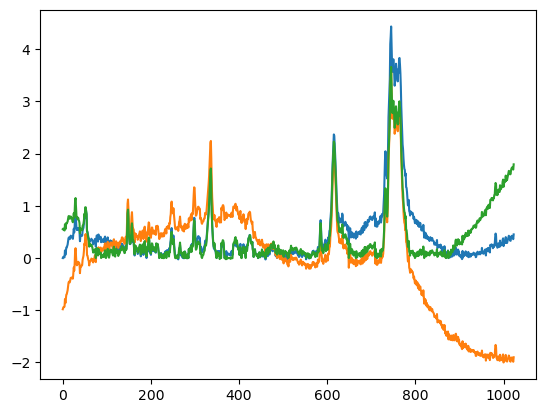

20


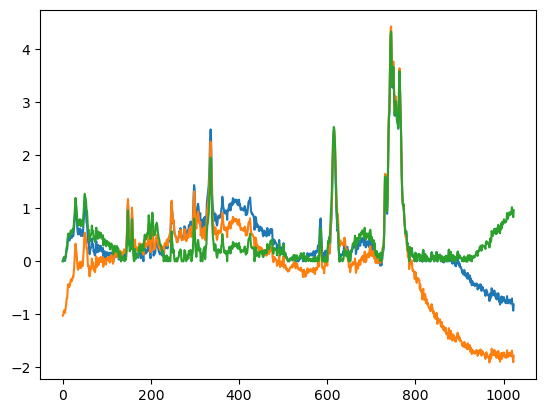

21


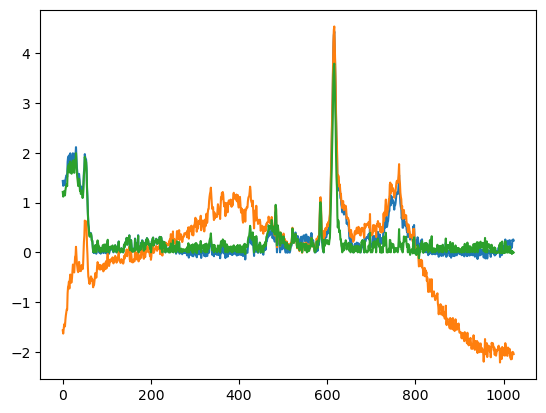

22


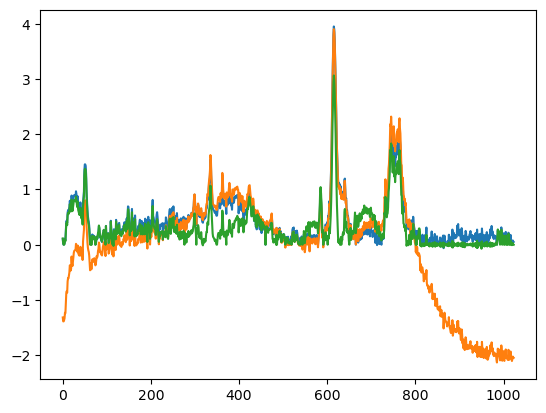

23


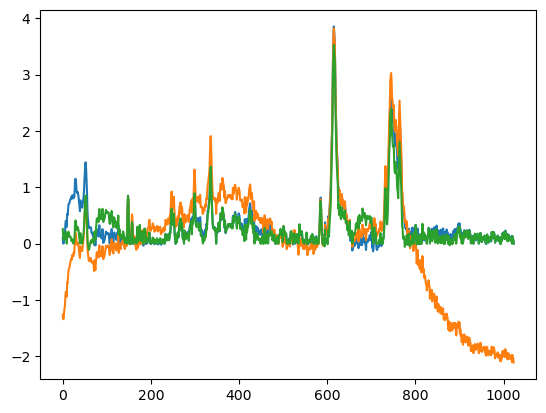

24


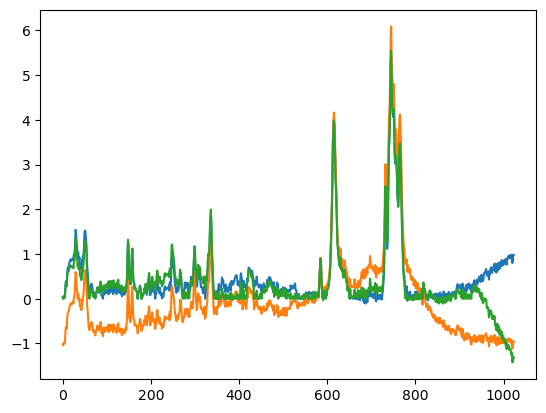

25


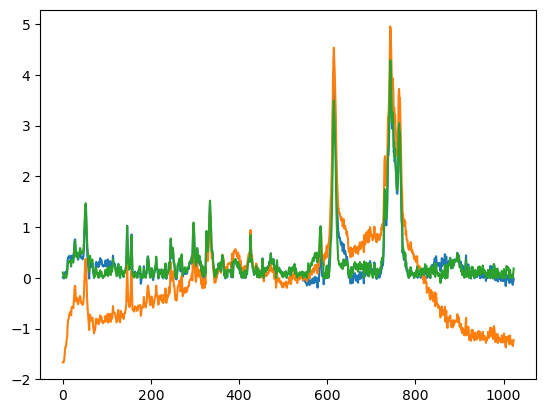

26


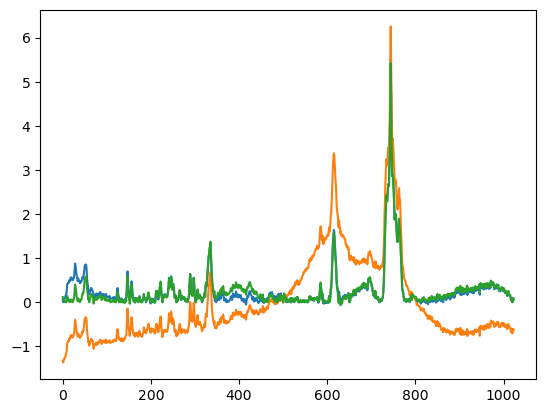

27


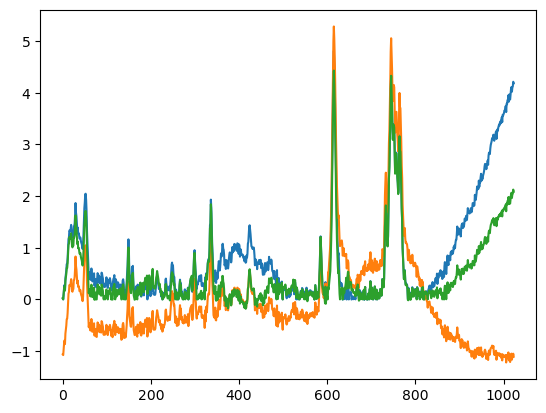

28


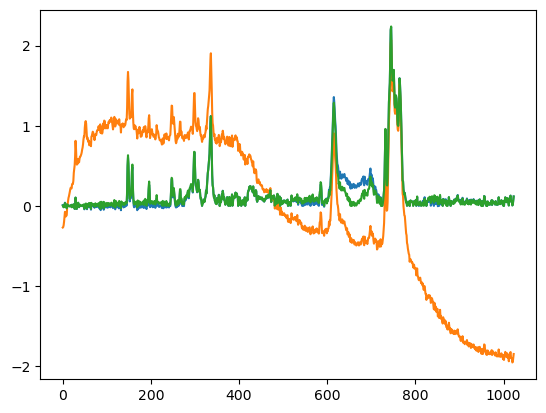

29


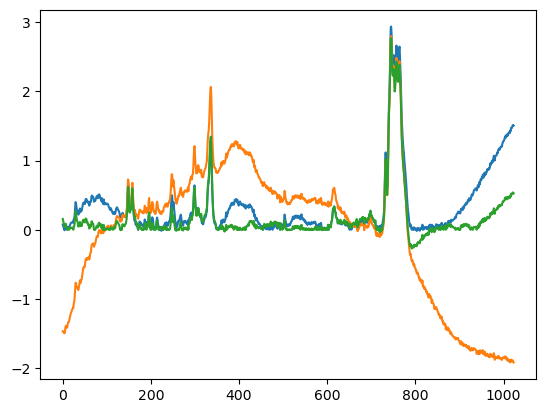

30


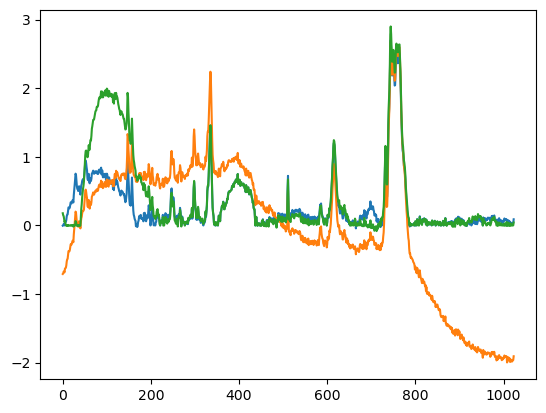

31


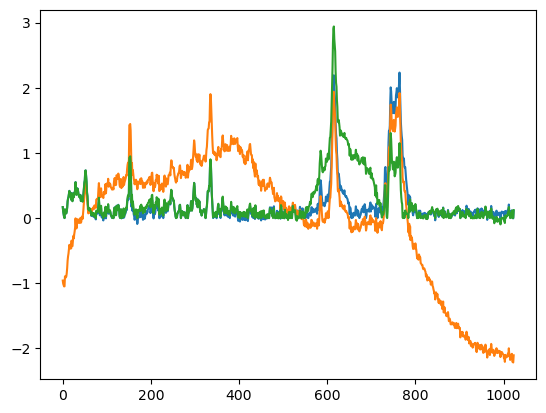

32


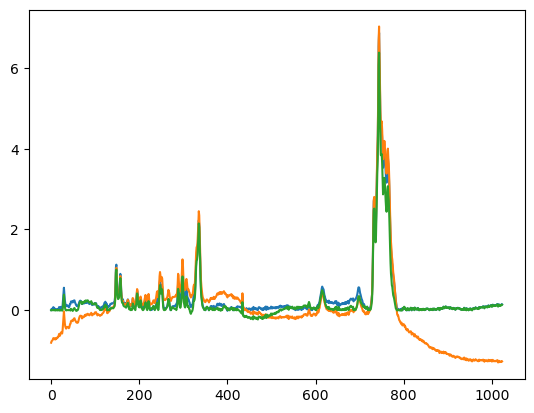

33


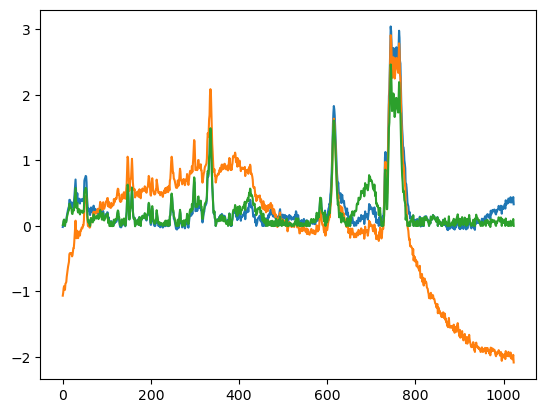

34


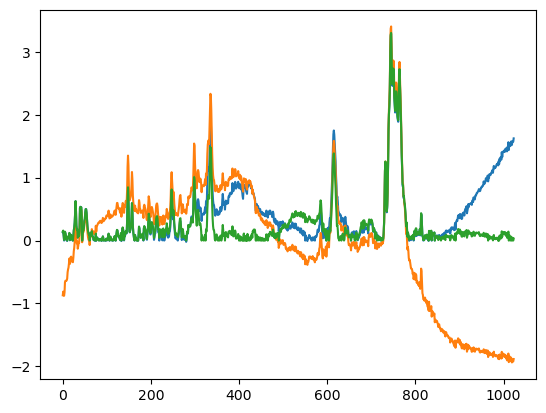

35


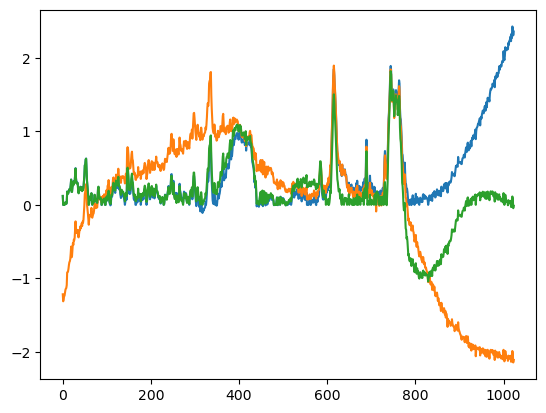

36


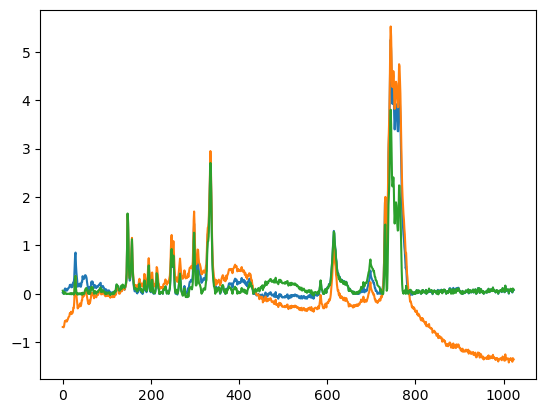

37


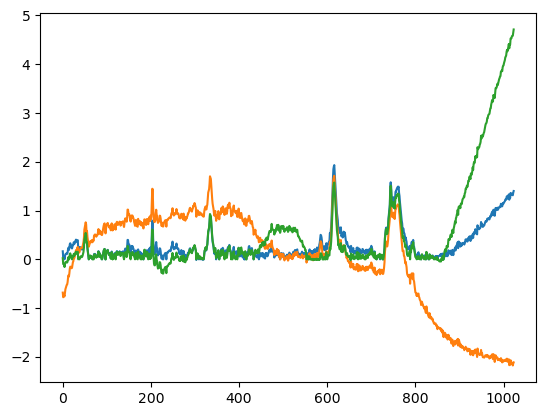

38


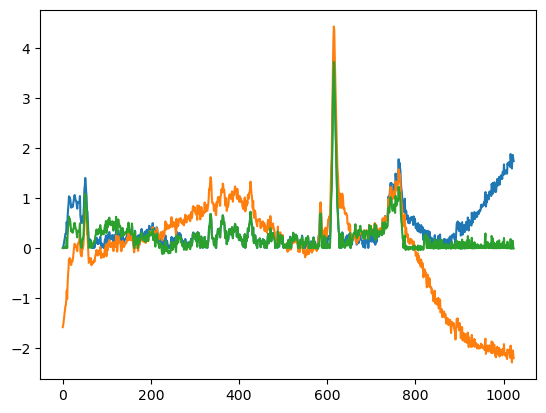

39


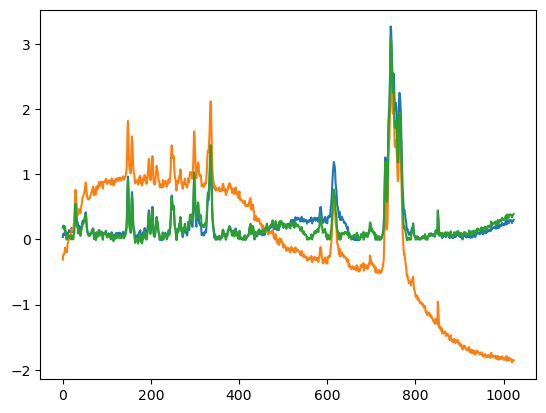

40


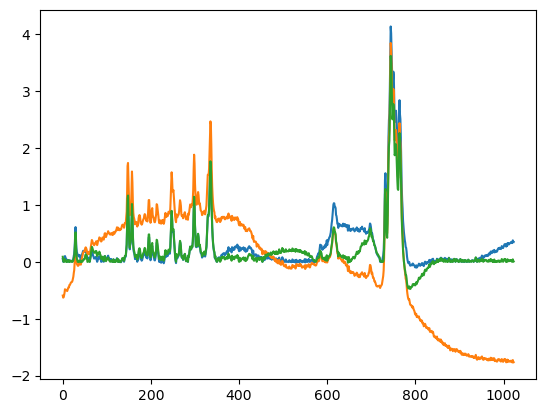

41


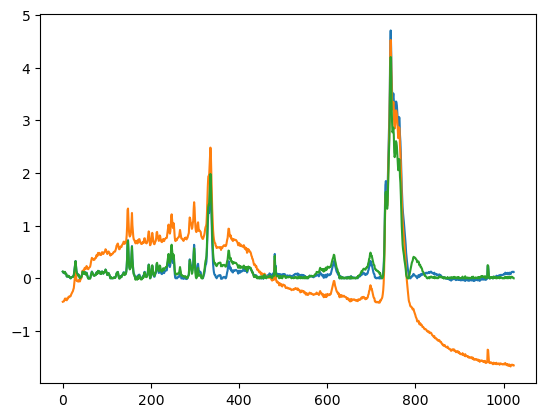

42


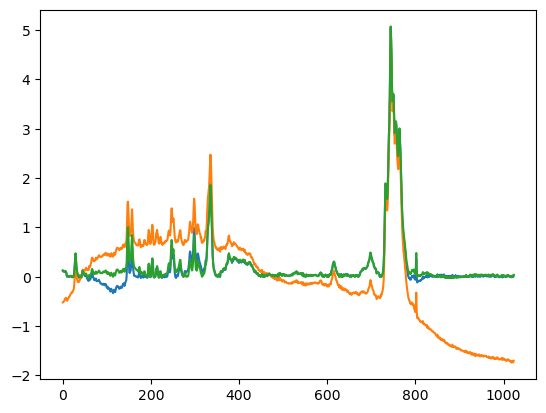

43


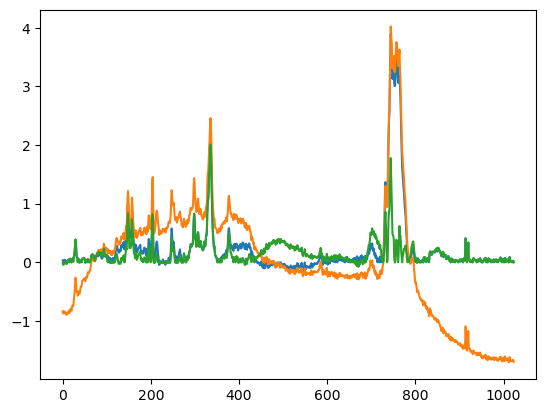

44


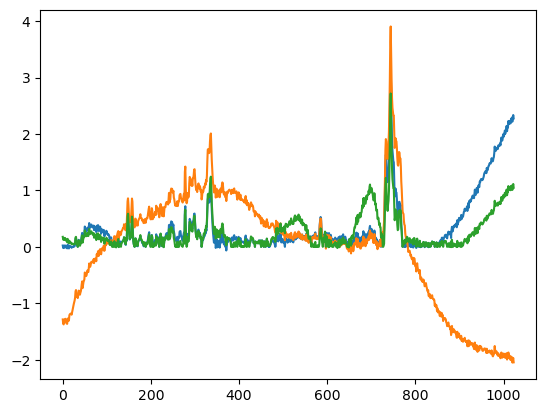

45


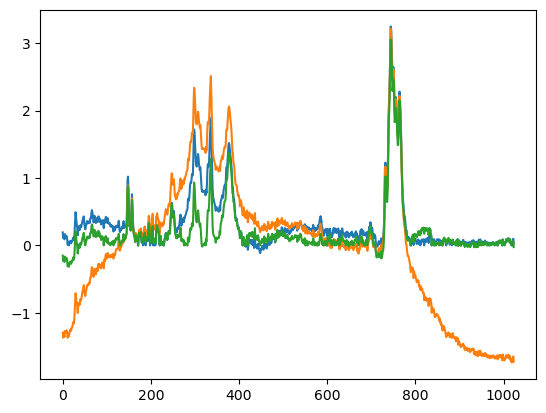

46


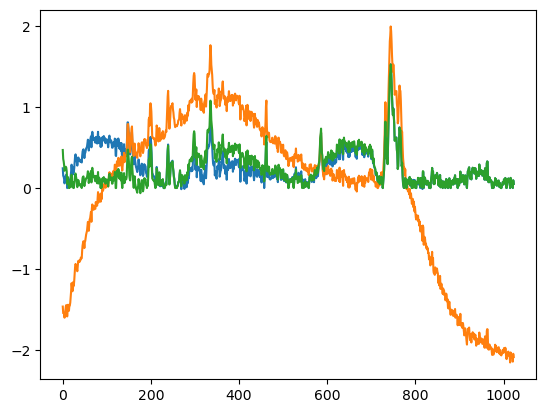

47


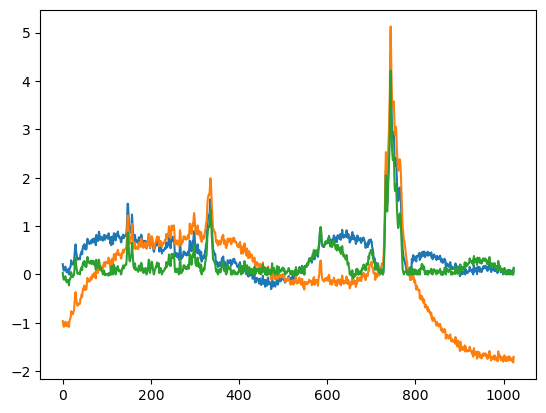

48


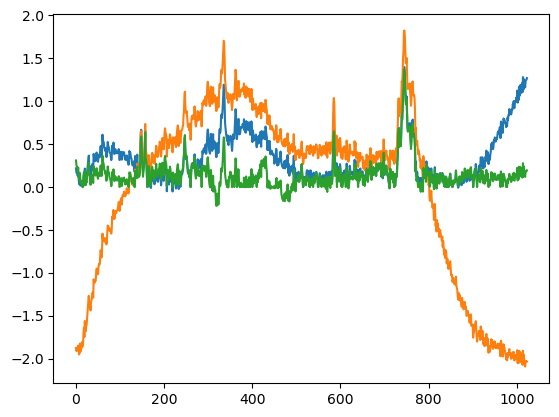

49


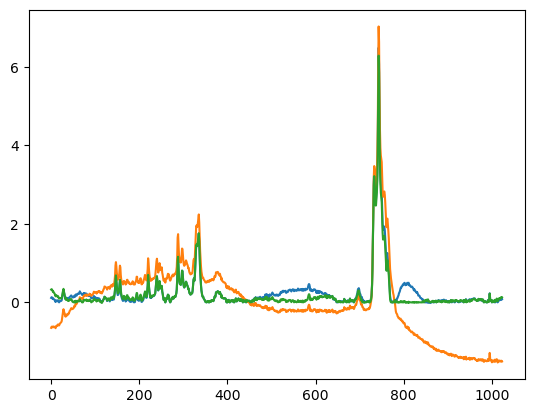

50


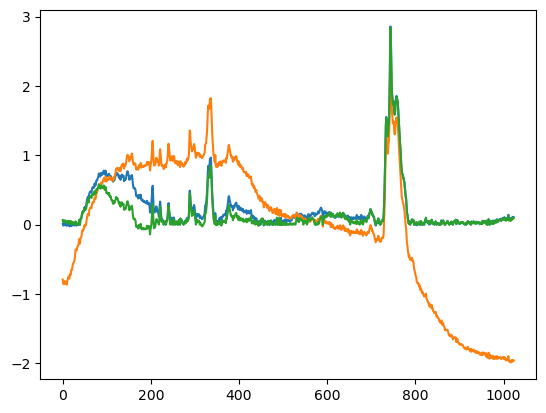

51


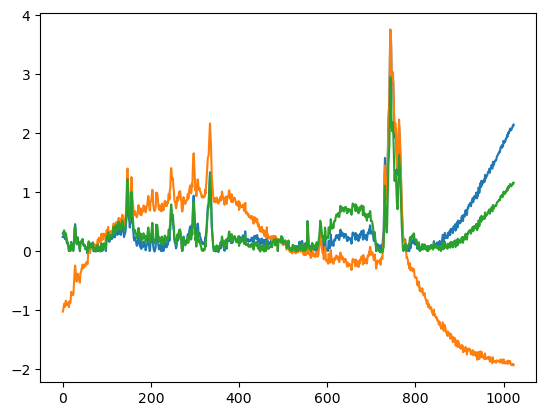

52


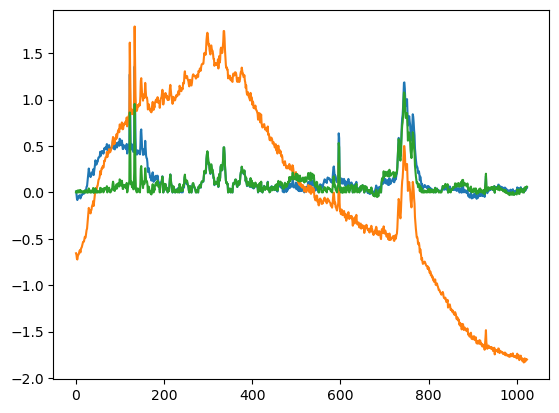

53


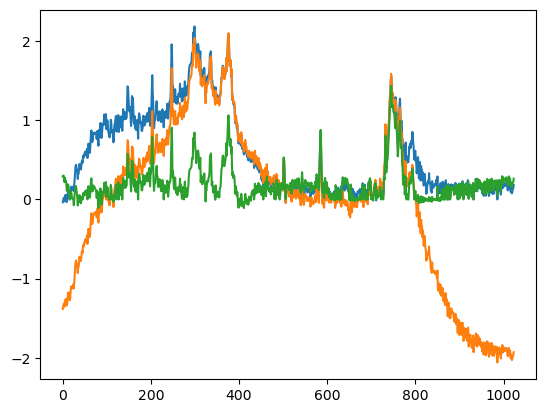

54


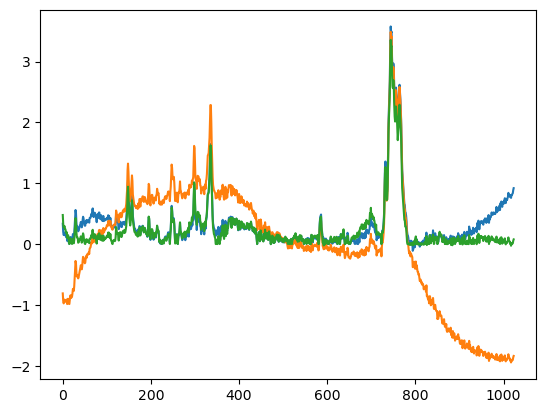

55


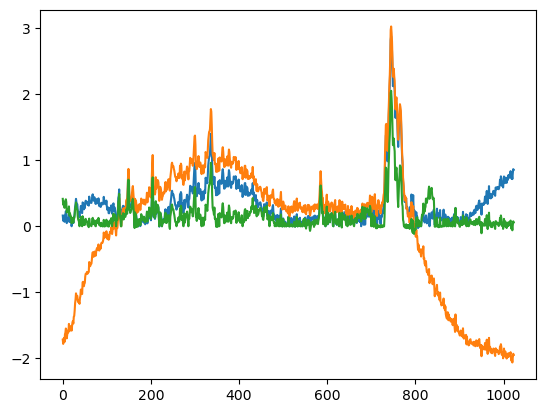

56


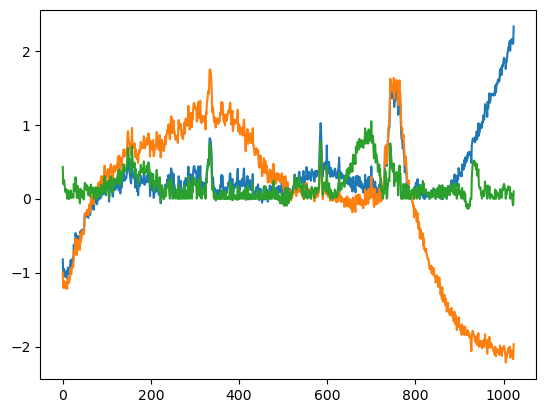

57


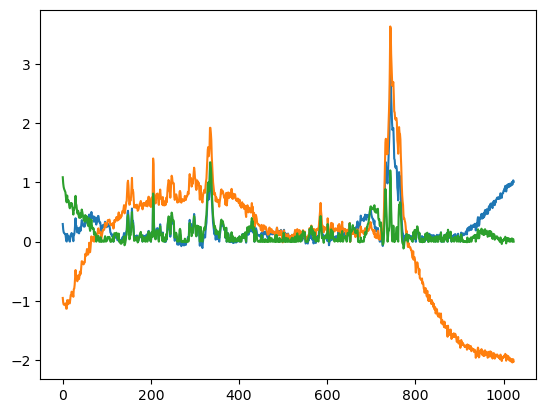

58


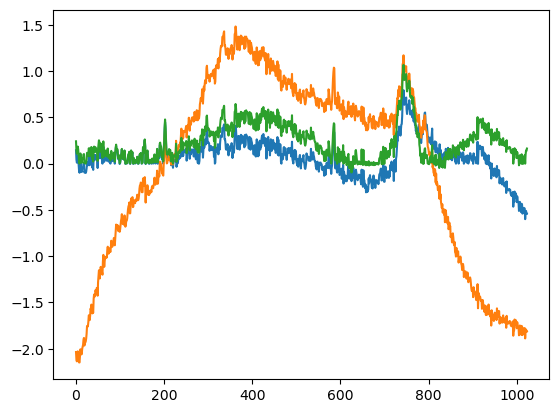

59


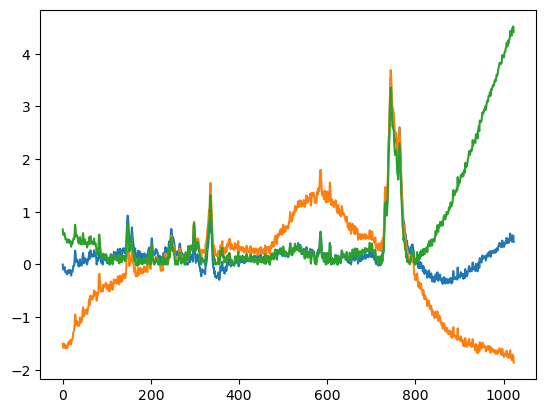

60


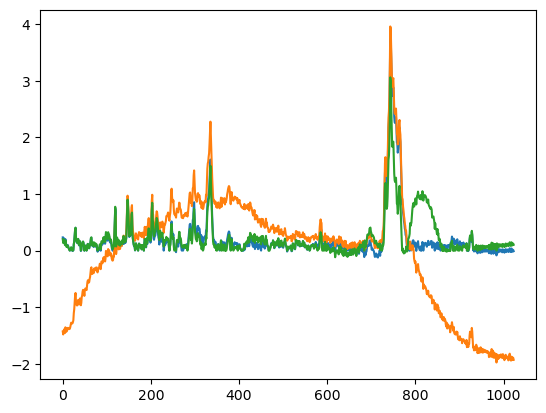

61


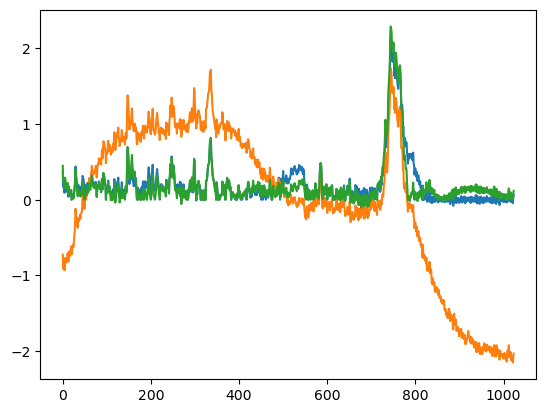

62


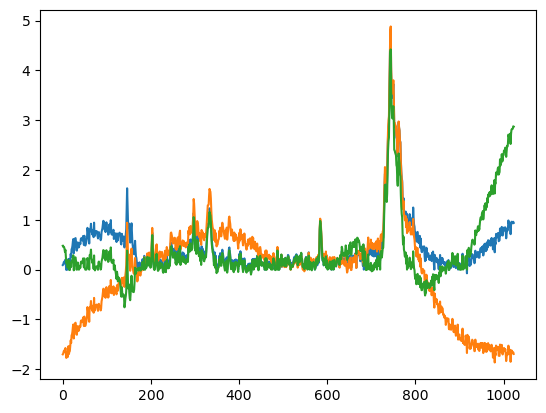

63


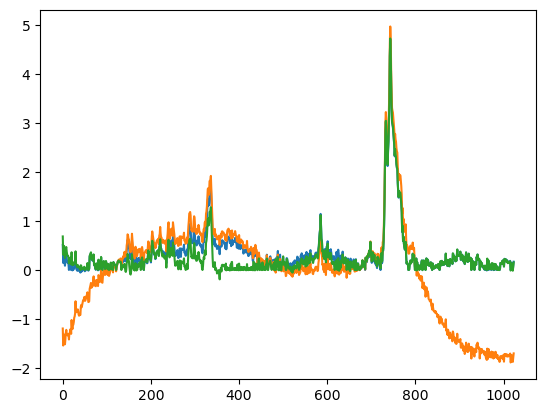

64


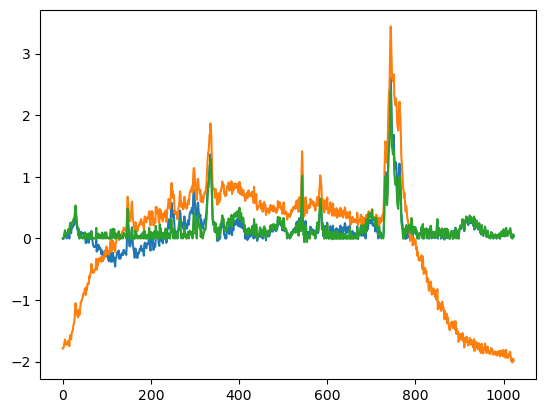

65


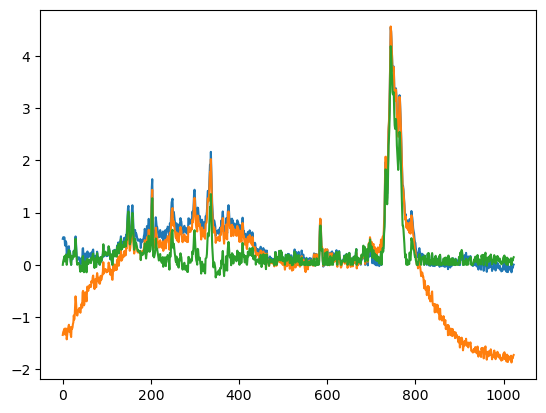

66


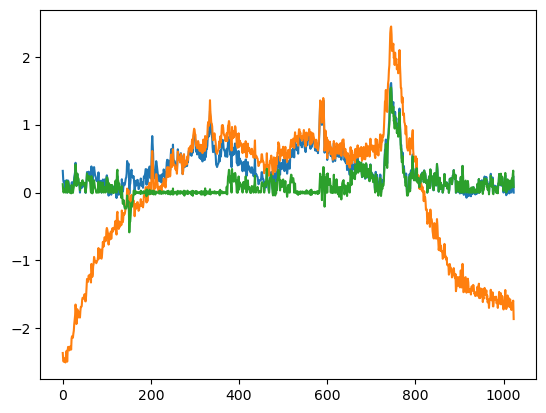

67


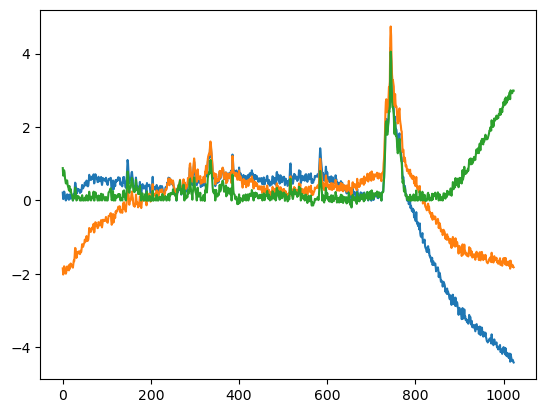

68


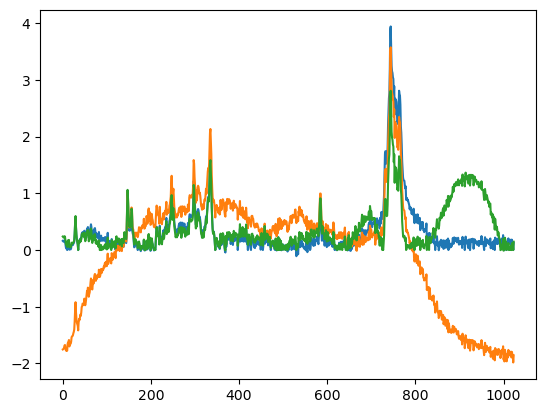

69


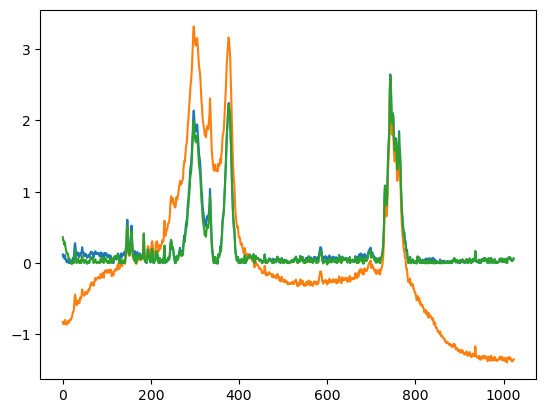

70


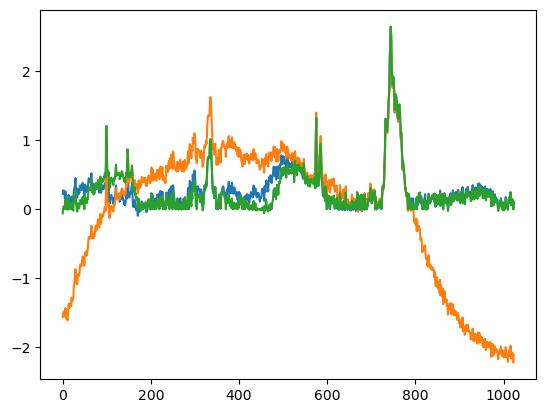

71


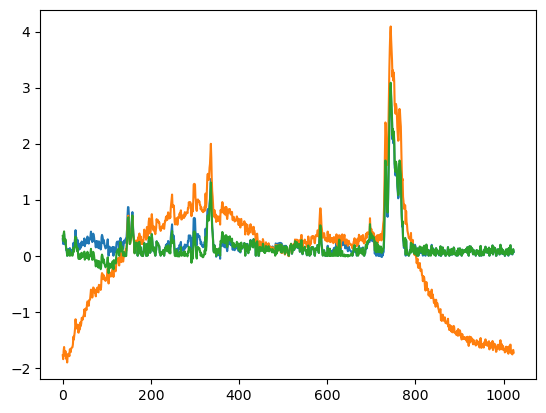

72


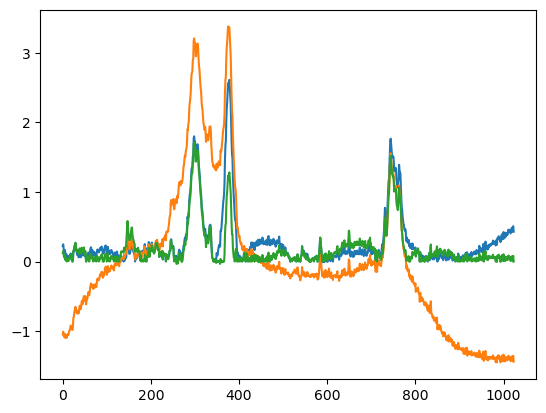

73


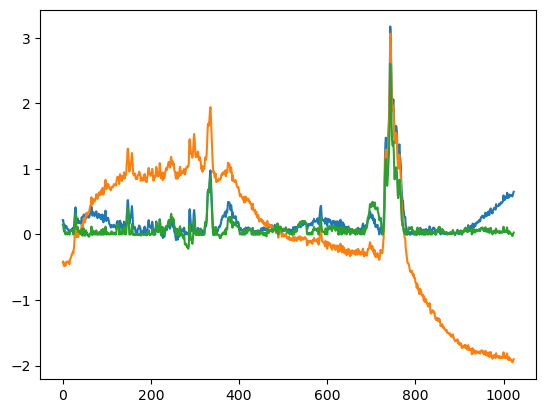

74


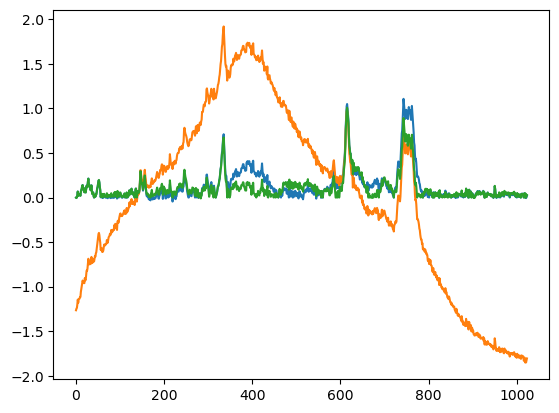

75


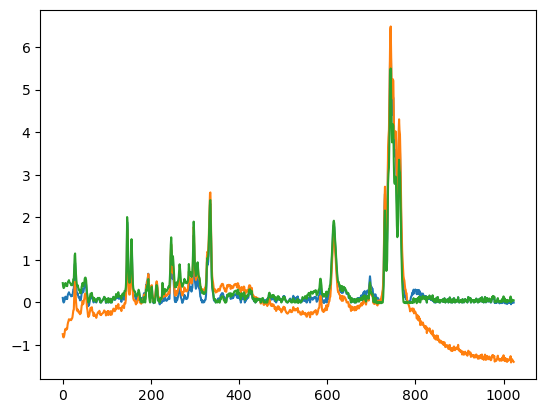

76


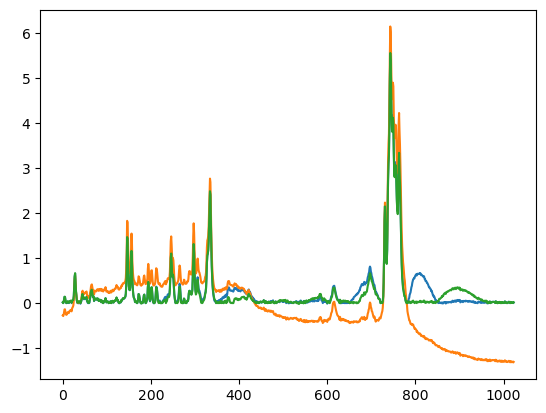

77


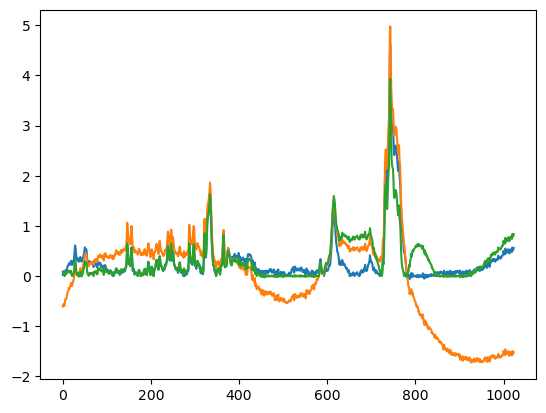

78


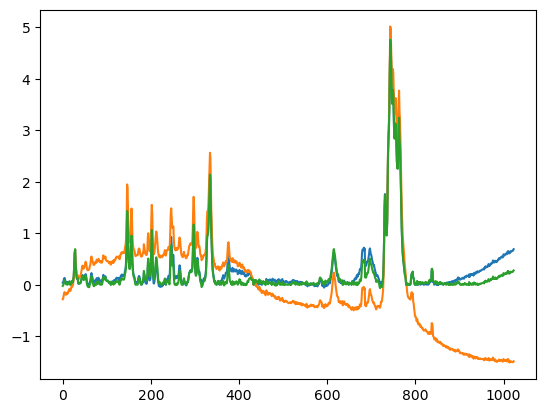

79


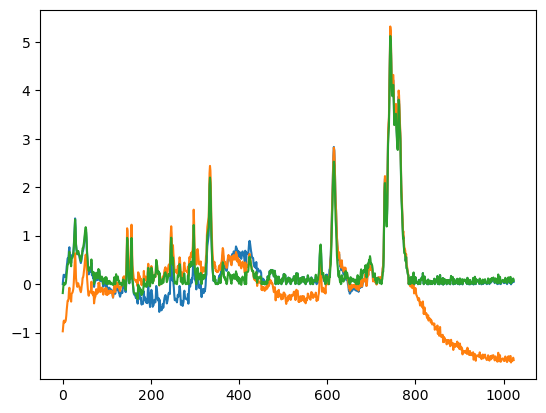

80


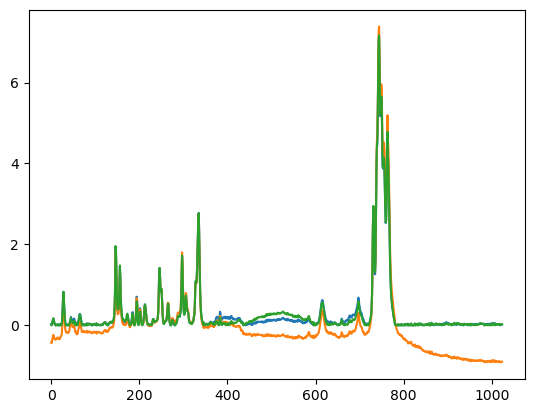

81


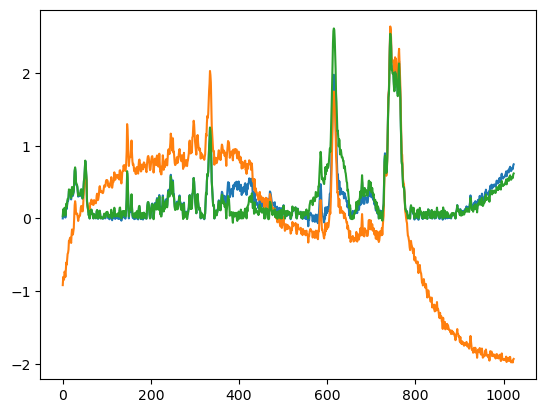

82


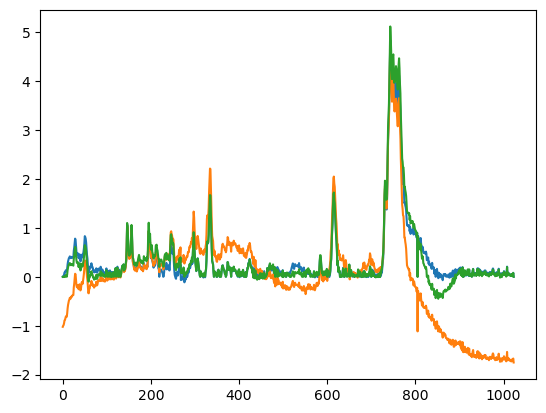

83


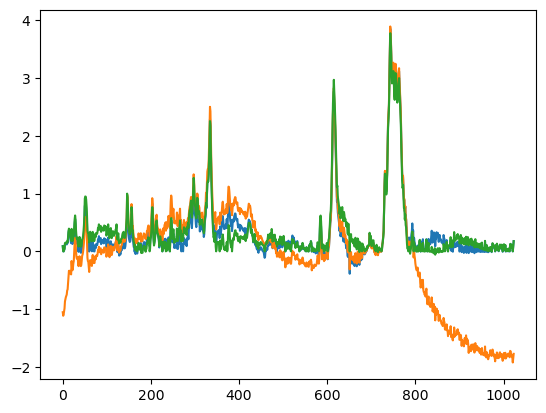

84


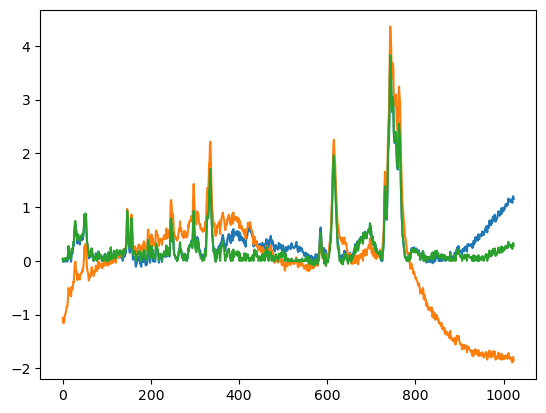

85


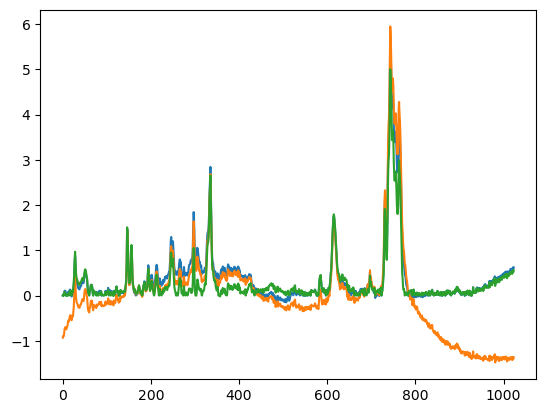

86


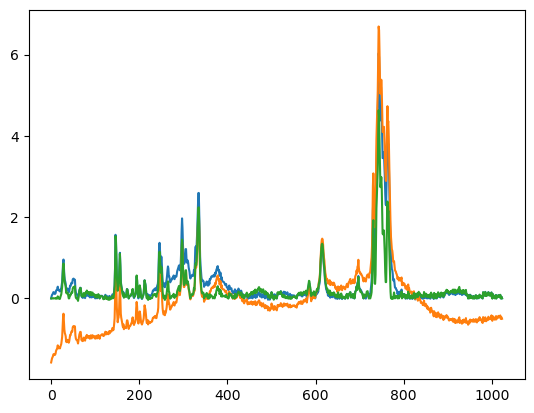

87


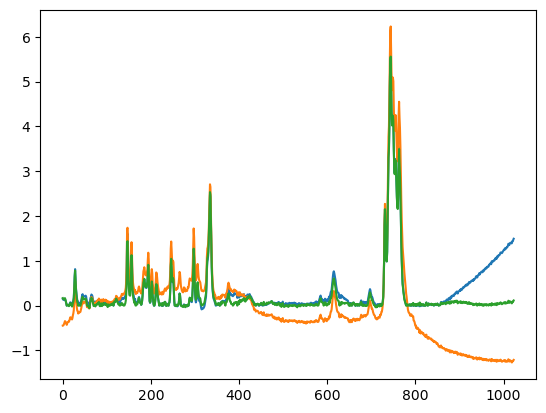

88


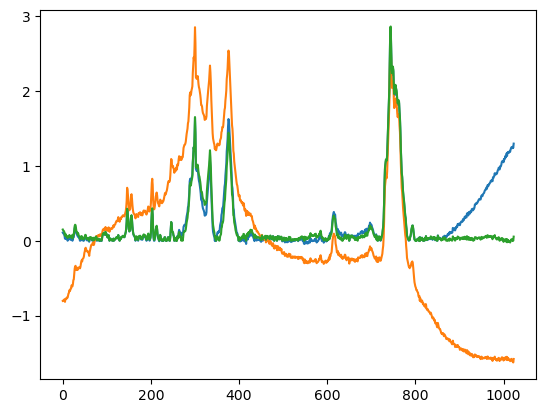

89


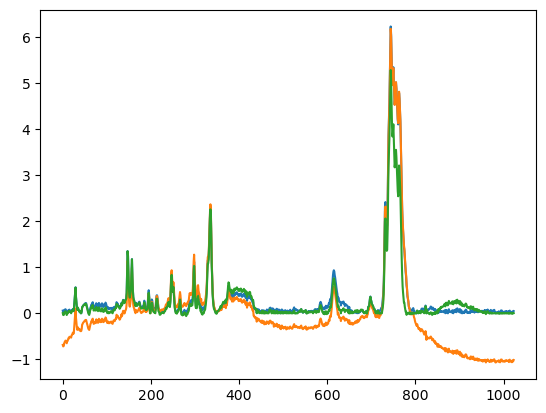

90


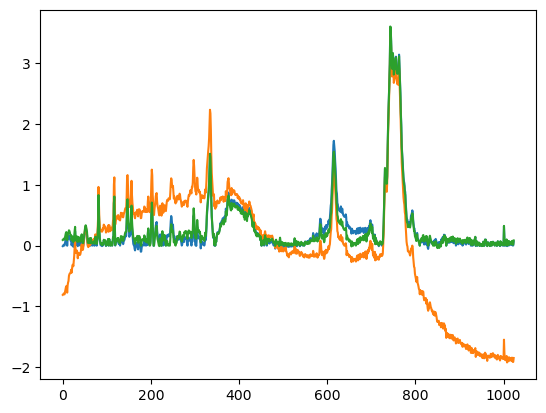

91


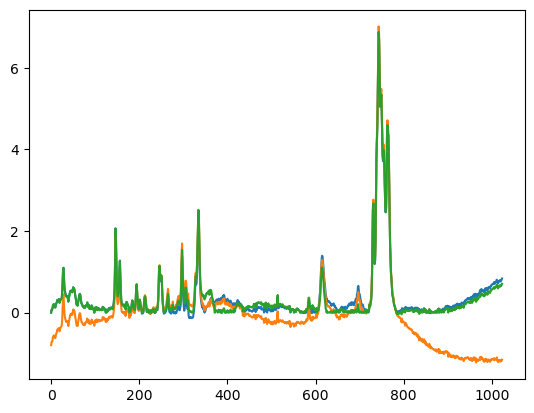

92


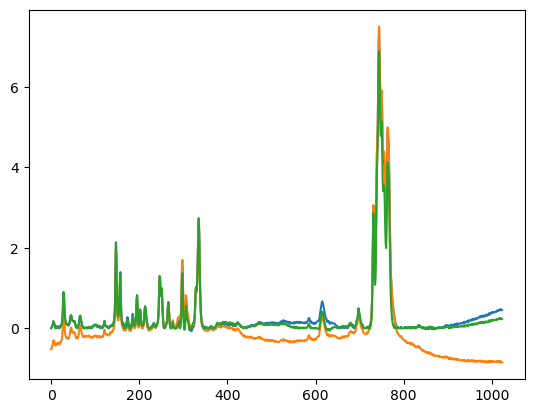

93


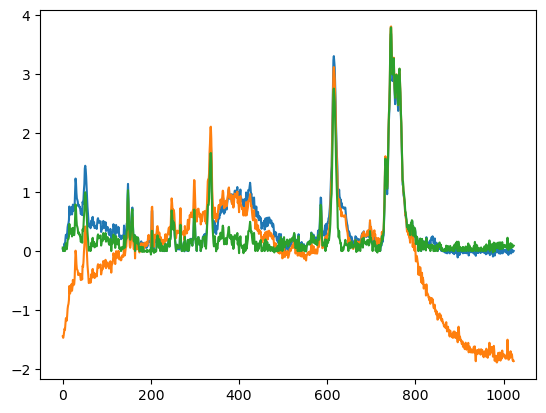

94


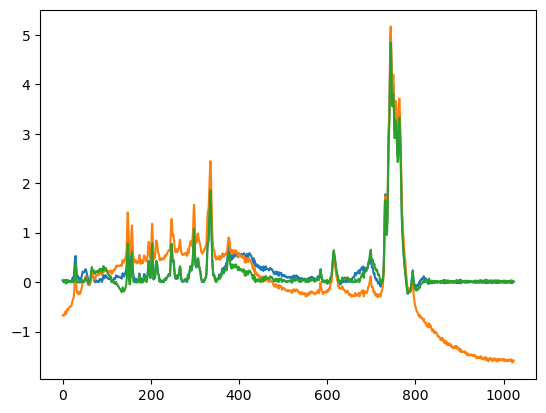

95


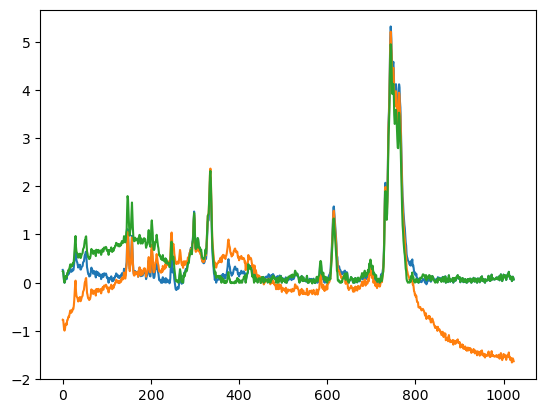

In [102]:
for i,s in enumerate(X_Raman_corrected[y == 'PP']):
    print(i)
    _ = plt.plot(s)
    _ = plt.plot(X_Raman[y == 'PP'][i,:])
    _ = plt.plot(X_Raman_corrected_2[y == 'PP'][i,:])
    _ = plt.show()


In [47]:
seed = 987
set_size_IR = []
for i in range(1):
    seed = seed + 1
    smx_all_IR = 1-np.abs(smx_nn(X_train_IR, X_IR, label_train_IR))

    quant_smx, rest_smx, quant_labels, rest_labels, idx_quant = split_cal_test(smx_all_IR, label_, cal_prop=0.2, seed=seed)
    smx_cal, smx_test, label_cal, label_test, idx = split_cal_test(rest_smx, rest_labels, cal_prop=0.8, seed=seed)

    n = smx_cal.shape[0]
    alpha = .25
    (prediction_sets, coverage), qhat = conform_prediction(smx_cal, smx_test, label_cal, n, alpha,label_test, cond=0)
    coverage, prediction_sets.sum(1).mean(), qhat
    set_size_IR.append(prediction_sets.sum(1).mean())
    
np.mean(set_size_IR), np.std(set_size_IR)

(1.1, 0.0)

In [48]:
prediction_sets_n_ir = [list(label_table.loc[ps,'polymer']) for ps in prediction_sets]
coverage,prediction_sets.sum(1).mean(), prediction_sets_n_ir

(0.74,
 1.1,
 [['PP'],
  ['PP'],
  ['LDPE', 'AFR'],
  ['PP'],
  ['LDPE', 'PP'],
  ['PP'],
  ['LDPE'],
  ['PSL'],
  ['LDPE'],
  ['LDPE'],
  ['PSL'],
  ['PP'],
  ['PSL'],
  ['LDPE'],
  ['LDPE'],
  ['LDPE'],
  ['PP'],
  ['LDPE'],
  ['LDPE'],
  ['LDPE'],
  ['LDPE'],
  ['LDPE'],
  ['LDPE'],
  ['LDPE'],
  ['LDPE', 'PP'],
  ['PP'],
  ['LDPE'],
  ['LDPE'],
  ['PSL'],
  ['LDPE'],
  ['PP'],
  ['LDPE'],
  ['LDPE'],
  ['PP'],
  ['LDPE'],
  ['LDPE'],
  ['PP'],
  ['PSL'],
  ['LDPE'],
  ['LDPE'],
  ['LDPE'],
  ['LDPE'],
  ['AFR'],
  ['LDPE'],
  ['LDPE'],
  ['PP'],
  ['PP'],
  ['PP'],
  ['NaNO3', 'PSL'],
  ['LDPE', 'PP']])

In [49]:
#seed = 0
set_size_Raman = []
for i in range(1):
    seed = seed + 1
    smx_all_Raman = 1-np.abs(smx_pcc(X_train_Raman, X_Raman_corrected_2, label_train_Raman))

    quant_smx, rest_smx, quant_labels, rest_labels, idx_quant = split_cal_test(smx_all_Raman, label_, cal_prop=0.2, seed=seed)
    smx_cal, smx_test, label_cal, label_test, idx = split_cal_test(rest_smx, rest_labels, cal_prop=0.8, seed=seed)

    n = smx_cal.shape[0]
    alpha = .25
    (prediction_sets, coverage), qhat = conform_prediction(smx_cal, smx_test, label_cal, n, alpha,label_test, cond=0)
    coverage, prediction_sets.sum(1).mean(), qhat
    set_size_Raman.append(prediction_sets.sum(1).mean())
    
np.mean(set_size_Raman), np.std(set_size_Raman)


(1.96, 0.0)

In [50]:
prediction_sets_n_raman = [list(label_table.loc[ps,'polymer']) for ps in prediction_sets]
coverage,prediction_sets.sum(1).mean(), prediction_sets_n_raman

(0.64,
 1.96,
 [['LDPE', 'PP'],
  ['PP', 'PSL'],
  ['LDPE', 'PP'],
  ['NaNO3', '(NH4)2SO4', 'AFR', 'Sucrose'],
  ['LDPE', 'PP'],
  ['NaNO3', '(NH4)2SO4', 'AFR', 'PP', 'Sucrose'],
  ['LDPE', 'PP'],
  ['LDPE', 'PP'],
  [],
  ['LDPE', 'PP'],
  [],
  ['LDPE', 'PP'],
  ['LDPE', 'PP', 'Sucrose', 'PSL'],
  ['LDPE', 'PP', 'PSL'],
  ['LDPE', 'PP'],
  ['NaNO3', '(NH4)2SO4', 'AFR', 'Sucrose'],
  [],
  ['LDPE', 'PP'],
  [],
  ['NaNO3', '(NH4)2SO4', 'AFR', 'Sucrose'],
  ['LDPE', 'PP'],
  ['NaNO3', '(NH4)2SO4', 'LDPE', 'AFR', 'PP'],
  [],
  ['LDPE', 'PP'],
  ['LDPE', 'PP'],
  ['LDPE', 'PP'],
  ['LDPE', 'PP'],
  ['LDPE', 'PP'],
  ['PP'],
  [],
  ['LDPE', 'PP'],
  ['LDPE', 'PP', 'Sucrose'],
  ['LDPE', 'PP', 'PSL'],
  ['LDPE', 'PP'],
  ['PP'],
  ['LDPE', 'PP'],
  [],
  ['LDPE', 'PP'],
  ['LDPE', 'PP'],
  ['LDPE', 'PP'],
  ['LDPE', 'PP'],
  ['LDPE', 'PP'],
  ['NaNO3', '(NH4)2SO4', 'AFR', 'Sucrose'],
  ['LDPE', 'PP'],
  [],
  [],
  [],
  ['PP', 'PSL'],
  ['LDPE', 'PP', 'Sucrose'],
  ['LDPE', 'PP']])

In [51]:
#smx_all_IR = 1-np.abs(smx_pcc(X_train_IR, X_IR, label_train_IR))
#smx_all_Raman = 1-np.abs(smx_pcc(X_train_Raman, X_Raman_corrected, label_train_Raman))
#smx_cal, smx_test, label_cal, label_test, idx = split_cal_test(smx_all, label_, cal_prop=0.5, seed=0)
score_list = [smx_all_IR, smx_all_Raman]

In [52]:
set_size = defaultdict(list)
cov = defaultdict(list)
cov_cal = defaultdict(list)
K=2
alpha=.25

for i in range(1):
    if i % 5 == 0:
        print(i)
        
    #seed = seed + i
    
    #score_list, y_train, y_test, top_views = simulate_s_2(N, d, d_v, L, scale, K, N_train, seed)
    #top_views = np.array(acc_list)
    quant_smx_list = []
    rest_smx_list = []
    cal_smx_list = []
    val_smx_list = []
        
    U_list = gen_u(K, seed=seed)
    
    for i in range(K):
    
        quant_smx, rest_smx, quant_labels, rest_labels, idx_quant = split_cal_test(score_list[i], label_, cal_prop=0.2, seed=seed)
        #print(quant_smx.shape, rest_smx.shape)
        cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(rest_smx, rest_labels, cal_prop=0.8, seed=seed)
        #print(cal_smx.shape, val_smx.shape)
        
        quant_smx_list.append(quant_smx)
        rest_smx_list.append(rest_smx)
        cal_smx_list.append(cal_smx)
        val_smx_list.append(val_smx)
        
    n = cal_labels.shape[0]
    
    for j in range(1,K):
        
        prediction_sets, empirical_coverage = mvcp_2(quant_smx_list[:(j+1)],
                                                     quant_labels,
                                                     cal_smx_list[:(j+1)], 
                                                     cal_labels, 
                                                     val_smx_list[:(j+1)], 
                                                     alpha, 
                                                     val_labels, 
                                                     U=U_list[0])
    
        set_size['mvcp'+str(j+1)].append(
            prediction_sets.sum(1).mean()
        )
        cov['mvcp'+str(j+1)].append(
            empirical_coverage
        )


0


In [53]:
np.mean(set_size['mvcp2'])

1.48

In [54]:
prediction_sets_n_mvcp = [list(label_table.loc[ps,'polymer']) for ps in prediction_sets]
empirical_coverage,prediction_sets.sum(1).mean(), prediction_sets_n_mvcp

(0.74,
 1.48,
 [['PP'],
  ['PP', 'PSL'],
  ['PP'],
  [],
  ['LDPE', 'PP'],
  ['LDPE'],
  ['PP'],
  ['LDPE', 'PP'],
  [],
  [],
  ['NaNO3', '(NH4)2SO4', 'AFR', 'Sucrose', 'PSL'],
  ['LDPE'],
  ['LDPE'],
  ['LDPE'],
  ['LDPE', 'PP'],
  [],
  [],
  ['PP', 'PSL'],
  [],
  ['NaNO3', '(NH4)2SO4', 'AFR', 'Sucrose'],
  ['LDPE'],
  ['LDPE'],
  [],
  ['PP'],
  ['LDPE'],
  ['PP'],
  ['PP'],
  ['LDPE'],
  ['NaNO3', '(NH4)2SO4', 'LDPE', 'AFR', 'PP', 'PSL'],
  ['Sucrose'],
  ['LDPE'],
  ['NaNO3', '(NH4)2SO4', 'LDPE', 'PP', 'Sucrose', 'PSL'],
  ['PP'],
  ['LDPE', 'PP'],
  ['LDPE'],
  ['LDPE'],
  ['PSL'],
  ['LDPE'],
  ['PP'],
  ['LDPE'],
  ['LDPE'],
  ['PP'],
  ['NaNO3', '(NH4)2SO4', 'LDPE', 'AFR', 'Sucrose'],
  ['LDPE', 'PP'],
  ['PP', 'PSL'],
  [],
  ['NaNO3', '(NH4)2SO4', 'AFR', 'Sucrose'],
  ['PSL'],
  ['LDPE'],
  ['PP']])

In [55]:
pd.DataFrame({'polymer':np.array(label_table.iloc[label_test,1]),
              'ir':prediction_sets_n_ir,
              'raman':prediction_sets_n_raman,
              'mvcp':prediction_sets_n_mvcp})

,polymer,ir,raman,mvcp
0,PP,[PP],"[LDPE, PP]",[PP]
1,PSL,[PP],"[PP, PSL]","[PP, PSL]"
2,PP,"[LDPE, AFR]","[LDPE, PP]",[PP]
3,PSL,[PP],"[NaNO3, (NH4)2SO4, AFR, Sucrose]",[]
4,PP,"[LDPE, PP]","[LDPE, PP]","[LDPE, PP]"
5,LDPE,[PP],"[NaNO3, (NH4)2SO4, AFR, PP, Sucrose]",[LDPE]
6,PP,[LDPE],"[LDPE, PP]",[PP]
7,PP,[PSL],"[LDPE, PP]","[LDPE, PP]"
8,PP,[LDPE],[],[]
9,LDPE,[LDPE],"[LDPE, PP]",[]


In [56]:

U_list = gen_u(2, seed=seed, n_th=100)


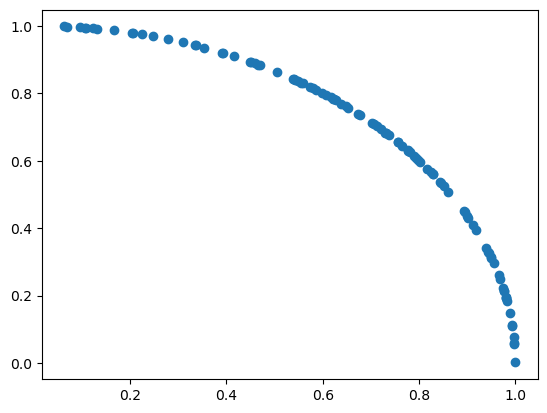

In [57]:
plt.scatter(U_list[0][:,0], U_list[0][:,1])

In [58]:
smx_all_IR = 1-np.abs(smx_nn(X_train_IR, X_IR, label_train_IR))
smx_all_Raman = 1-np.abs(smx_nn(X_train_Raman, X_Raman_corrected_2, label_train_Raman))
#smx_cal, smx_test, label_cal, label_test, idx = split_cal_test(smx_all, label_, cal_prop=0.5, seed=0)
score_list = [smx_all_IR, smx_all_Raman]

In [59]:
np.mean(np.argmin(np.max(np.array([smx_all_IR, smx_all_Raman]),0), 1) == label_)

0.6872964169381107

In [60]:
np.mean(np.argmin(smx_all_IR, 1) == label_)

0.7263843648208469

In [61]:
np.mean(np.argmin(smx_all_Raman, 1) == label_)

0.3583061889250814

(array([1.87486582, 7.38765934, 2.14147518, 1.59965615, 1.19544197,
        0.68802415, 0.42141479, 0.23220815, 0.17200604, 0.12900453]),
 array([0.03558107, 0.09870538, 0.1618297 , 0.22495401, 0.28807832,
        0.35120264, 0.41432695, 0.47745127, 0.54057558, 0.6036999 ,
        0.66682421]),
 <BarContainer object of 10 artists>)

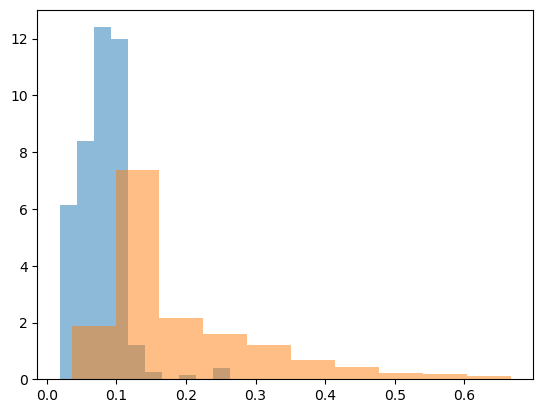

In [62]:
plt.hist(score_list[0][np.arange(307), label_], alpha=.5, density=True)
plt.hist(score_list[0][(label_[:, None] != np.arange(7)[None,:])], alpha=.5, density=True)

(array([ 1.990663  ,  4.71472815, 16.309467  , 13.89971706,  9.67392368,
         6.88001071,  5.34335857,  3.07330427,  1.67634779,  0.76832607]),
 array([0.06390525, 0.07945014, 0.09499502, 0.11053991, 0.12608479,
        0.14162967, 0.15717456, 0.17271944, 0.18826433, 0.20380921,
        0.21935409]),
 <BarContainer object of 10 artists>)

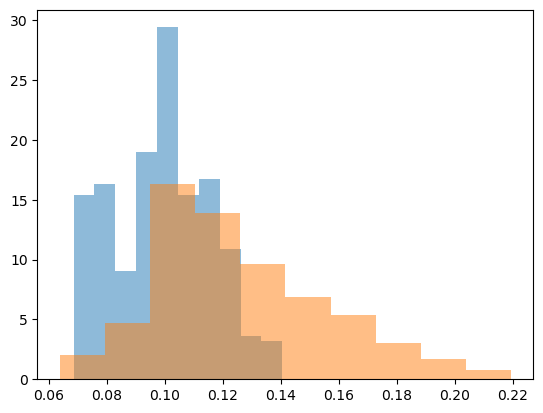

In [63]:
plt.hist(score_list[1][np.arange(307), label_], alpha=.5, density=True)
plt.hist(score_list[1][(label_[:, None] != np.arange(7)[None,:])], alpha=.5, density=True)

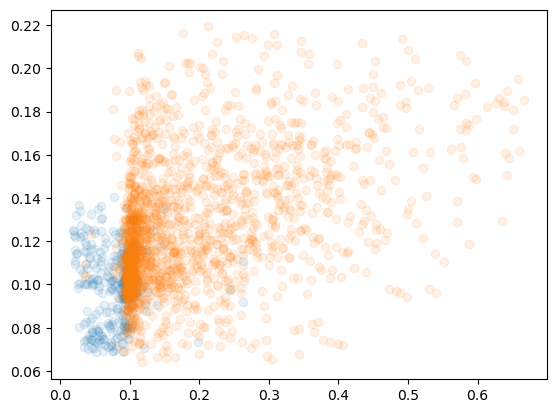

In [64]:
plt.scatter(score_list[0][np.arange(307), label_], score_list[1][np.arange(307), label_], alpha=.1)

plt.scatter(score_list[0][(label_[:, None] != np.arange(7)[None,:])],
score_list[1][(label_[:, None] != np.arange(7)[None,:])], alpha=.1)

In [77]:
smx_all_IR = 1-np.power(smx_pcc(X_train_IR, X_IR, label_train_IR),2)
smx_all_Raman = 1-np.power(smx_pcc(X_train_Raman, X_Raman_corrected_2, label_train_Raman),2)
#smx_cal, smx_test, label_cal, label_test, idx = split_cal_test(smx_all, label_, cal_prop=0.5, seed=0)
score_list = [smx_all_IR, smx_all_Raman]

In [78]:
set_size = defaultdict(list)
set_size_all = defaultdict(list)
zero_sets = defaultdict(list)
cov = defaultdict(list)
cov_cal = defaultdict(list)
set_size_by_label_hqi = defaultdict(list)
K=2
alpha=.2
U_list = gen_u(K, seed=0)
seed = 0
for l in range(100):
    if l % 5 == 0:
        print(l)
        
    seed = seed + l
    
    #score_list, y_train, y_test, top_views = simulate_s_2(N, d, d_v, L, scale, K, N_train, seed)
    #top_views = np.array(acc_list)
    quant_smx_list = []
    rest_smx_list = []
    cal_smx_list = []
    val_smx_list = []
        
    
    for i in range(K):
    
        quant_smx, rest_smx, quant_labels, rest_labels, idx_quant = split_cal_test(score_list[i], label_, cal_prop=0.5, seed=seed)
        #print(quant_smx.shape, rest_smx.shape)
        cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(rest_smx, rest_labels, cal_prop=0.8, seed=seed)
        #print(cal_smx.shape, val_smx.shape)
        
        quant_smx_list.append(quant_smx)
        rest_smx_list.append(rest_smx)
        cal_smx_list.append(cal_smx)
        val_smx_list.append(val_smx)
        
    n = cal_labels.shape[0]
    
    for j in range(1,K):
        
        prediction_sets, empirical_coverage = mvcp_2(quant_smx_list[:(j+1)],
                                                     quant_labels,
                                                     cal_smx_list[:(j+1)], 
                                                     cal_labels, 
                                                     val_smx_list[:(j+1)], 
                                                     alpha, 
                                                     val_labels, 
                                                     U=U_list[0])
    
        
    
        set_size['mvcp'+str(j+1)].append(
            prediction_sets.sum(1).mean()
        )
        set_size_all['mvcp'+str(j+1)].append(
            prediction_sets.sum(1)
        )
        zero_sets['mvcp'+str(j+1)].append(
            np.mean(prediction_sets.sum(1) == 0)
        )
        cov['mvcp'+str(j+1)].append(
            empirical_coverage
        )
        
        set_size_by_label_hqi['mvcp'+str(j+1)].append(
            pd.DataFrame({'label':val_labels, 
                          'set_size':prediction_sets.sum(1)}).groupby('label').mean()
        )
        
        s_u = rest_smx_list[:(j+1)][0]
        #print(top_views[:(j+1)])
        #print(np.argmax(top_views[:(j+1)]))
        
        cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(s_u, rest_labels, cal_prop=0.8, seed=seed)
        n = cal_smx.shape[0]
        (prediction_sets, empirical_coverage), qhat = conform_prediction(cal_smx, val_smx, cal_labels, n, alpha, val_labels, cond=0)
        set_size['view_IR'+str(j+1)].append(prediction_sets.sum(1).mean())
        
        set_size_all['view_IR'+str(j+1)].append(
            prediction_sets.sum(1)
        )
        
        zero_sets['view_IR'+str(j+1)].append(np.mean(prediction_sets.sum(1) == 0))
        cov['view_IR'+str(j+1)].append(empirical_coverage)
        
        set_size_by_label_hqi['view_IR'+str(j+1)].append(
            pd.DataFrame({'label':val_labels, 
                          'set_size':prediction_sets.sum(1)}).groupby('label').mean()
        )
        
        s_u = rest_smx_list[:(j+1)][1]
        #print(top_views[:(j+1)])
        #print(np.argmax(top_views[:(j+1)]))
        
        cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(s_u, rest_labels, cal_prop=0.8, seed=seed)
        n = cal_smx.shape[0]
        (prediction_sets, empirical_coverage), qhat = conform_prediction(cal_smx, val_smx, cal_labels, n, alpha, val_labels, cond=0)
        set_size['view_Raman'+str(j+1)].append(prediction_sets.sum(1).mean())
        
        set_size_all['view_Raman'+str(j+1)].append(
            prediction_sets.sum(1)
        )
        
        zero_sets['view_Raman'+str(j+1)].append(np.mean(prediction_sets.sum(1) == 0))
        cov['view_Raman'+str(j+1)].append(empirical_coverage)
        
        s_u = np.sum(rest_smx_list[:(j+1)], 0)
        
        cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(s_u, rest_labels, cal_prop=0.8, seed=seed)
        n = cal_smx.shape[0]
        (prediction_sets, empirical_coverage), qhat = conform_prediction(cal_smx, val_smx, cal_labels, n, alpha, val_labels, cond=0)
        set_size['sum'+str(j+1)].append(prediction_sets.sum(1).mean())
        zero_sets['sum'+str(j+1)].append(np.mean(prediction_sets.sum(1) == 0))
        cov['sum'+str(j+1)].append(empirical_coverage)
        
        s_u = np.power(rest_smx_list[:(j+1)],2).sum(0)
        
        cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(s_u, rest_labels, cal_prop=0.8, seed=seed)
        n = cal_smx.shape[0]
        (prediction_sets, empirical_coverage), qhat = conform_prediction(cal_smx, val_smx, cal_labels, n, alpha, val_labels, cond=0)
        set_size['norm'+str(j+1)].append(prediction_sets.sum(1).mean())
        zero_sets['norm'+str(j+1)].append(np.mean(prediction_sets.sum(1) == 0))
        cov['norm'+str(j+1)].append(empirical_coverage)
        
        #s_u = s_pre_fused[j-1][~idx_quant,:]
        
        #cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(s_u, rest_labels, cal_prop=0.8, seed=seed)
        #n = cal_smx.shape[0]
        #(prediction_sets, empirical_coverage), qhat = conform_prediction(cal_smx, val_smx, cal_labels, n, alpha, val_labels, cond=0)
        #set_size['pre_fused'+str(j+1)].append(prediction_sets.sum(1).mean())
        #cov['pre_fused'+str(j+1)].append(empirical_coverage)


0
5
10
15
20
25
30
35
40
45
50
55
60
65
70
75
80
85
90
95


In [35]:
for alpha in alphas[9:]:#, cov_by_label_hqi2[0.05]]:
    dfs = cov_by_label_hqi[alpha]
    cov_by_label_table = (pd.concat(dfs).
     groupby('label').
     mean().
     merge(label_table_adaptive, left_index=True, right_on='label'))#.
     #merge(pd.concat(set_size_by_label[0.06076923076923077]).groupby('label').count(), left_on='id', right_on='label'))
    del cov_by_label_table['label']
    cov_by_label_table.columns = ['cov ' + str(round(100*(1-alpha))), 'polymer']
    cov_by_label_table = np.round(cov_by_label_table.set_index('polymer').sort_values('cov ' + str(round(100*(1-alpha)))), 2)
    cov_by_label_list.append(cov_by_label_table)
    
pd.concat(cov_by_label_list, axis=1).sort_index()

NameError: name 'alphas' is not defined

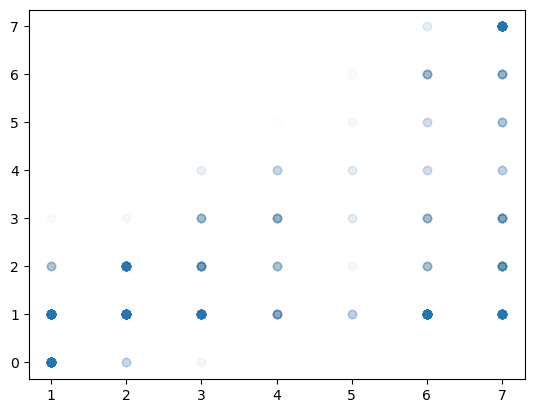

In [67]:
plt.scatter(np.concatenate(set_size_all['view_Raman2']),
            np.concatenate(set_size_all['mvcp2']), alpha=.01)

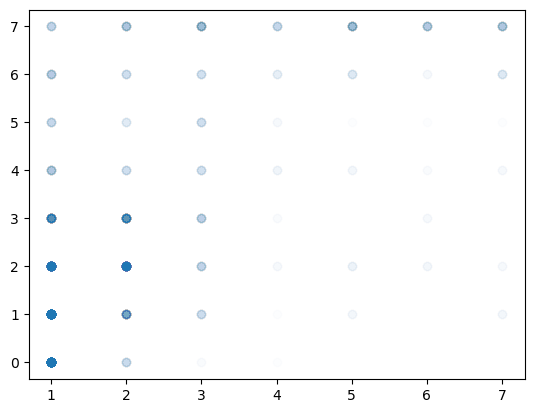

In [68]:
plt.scatter(np.concatenate(set_size_all['view_IR2']),
            np.concatenate(set_size_all['mvcp2']), alpha=.01)

In [30]:
set_size_by_label_hqi['mvcp2'][0]

,set_size
label,
2,2.500000
4,1.714286
6,5.444444


In [31]:
pd.concat(set_size_by_label_hqi['mvcp2']).groupby('label').mean()

,set_size
label,
2,1.815679
4,1.786178
6,5.035842


In [32]:
pd.concat(set_size_by_label_hqi['view_IR2']).groupby('label').mean()

,set_size
label,
2,1.750908
4,1.737252
6,4.441251


In [33]:
pd.DataFrame(pd.DataFrame(set_size).mean()).T

,mvcp2,view_IR2,view_Raman2,sum2,norm2
0,2.720968,2.508387,4.364194,2.541613,2.587419


In [71]:
df_res = pd.DataFrame(pd.DataFrame(zero_sets).mean()).reset_index()
df_res['cp'] = [s[:-1] for s in df_res['index']]
df_res['M'] = [s[-1] for s in df_res['index']]
del df_res['index']
df_res = df_res.pivot(index='M', columns='cp', values=0).loc[:,['view_IR','view_Raman','sum','norm', 'mvcp']]
df_res

cp,view_IR,view_Raman,sum,norm,mvcp
M,,,,,
2,0.0,0.0,0.007742,0.020645,0.053548


In [137]:
df_res = pd.DataFrame(pd.DataFrame(set_size).mean()).reset_index()
df_res['cp'] = [s[:-1] for s in df_res['index']]
df_res['M'] = [s[-1] for s in df_res['index']]
del df_res['index']
df_res = df_res.pivot(index='M', columns='cp', values=0).loc[:,['view_IR','view_Raman','sum','norm', 'mvcp']]
df_res

cp,view_IR,view_Raman,sum,norm,mvcp
M,,,,,
2,3.257419,4.432903,2.994839,3.074516,3.011935


In [138]:
df_res = pd.DataFrame(pd.DataFrame(set_size).mean()).reset_index()
df_res['cp'] = [s[:-1] for s in df_res['index']]
df_res['M'] = [s[-1] for s in df_res['index']]
del df_res['index']
df_res = df_res.pivot(index='M', columns='cp', values=0).loc[:,['view_IR','view_Raman', 'mvcp']]
df_res

cp,view_IR,view_Raman,mvcp
M,,,
2,3.257419,4.432903,3.011935


In [139]:
df_res = pd.DataFrame(pd.DataFrame(set_size).std()).reset_index()
df_res['cp'] = [s[:-1] for s in df_res['index']]
df_res['M'] = [s[-1] for s in df_res['index']]
del df_res['index']
df_res = df_res.pivot(index='M', columns='cp', values=0).loc[:,['view_IR','view_Raman', 'mvcp']]
df_res

cp,view_IR,view_Raman,mvcp
M,,,
2,0.52727,0.462313,0.460113


In [140]:
df_res = pd.DataFrame(pd.DataFrame(cov).mean()).reset_index()
df_res['cp'] = [s[:-1] for s in df_res['index']]
df_res['M'] = [s[-1] for s in df_res['index']]
del df_res['index']
df_res = df_res.pivot(index='M', columns='cp', values=0).loc[:,['view_IR','view_Raman', 'mvcp']]
df_res

cp,view_IR,view_Raman,mvcp
M,,,
2,0.909677,0.908387,0.905806


In [73]:
df_res = pd.DataFrame(pd.DataFrame(set_size).mean()).reset_index()
df_res['cp'] = [s[:-1] for s in df_res['index']]
df_res['M'] = [s[-1] for s in df_res['index']]
del df_res['index']
df_res = df_res.pivot(index='M', columns='cp', values=0).loc[:,['view_IR','view_Raman', 'mvcp']]
df_res

cp,view_IR,view_Raman,mvcp
M,,,
2,3.372581,2.772581,2.961935


In [79]:
df_res = pd.DataFrame(pd.DataFrame(set_size).mean()).reset_index()
df_res['cp'] = [s[:-1] for s in df_res['index']]
df_res['M'] = [s[-1] for s in df_res['index']]
del df_res['index']
df_res = df_res.pivot(index='M', columns='cp', values=0).loc[:,['view_IR','view_Raman', 'mvcp']]
df_res

cp,view_IR,view_Raman,mvcp
M,,,
2,3.372581,2.772581,2.961935


In [74]:
df_res = pd.DataFrame(pd.DataFrame(cov).mean()).reset_index()
df_res['cp'] = [s[:-1] for s in df_res['index']]
df_res['M'] = [s[-1] for s in df_res['index']]
del df_res['index']
df_res = df_res.pivot(index='M', columns='cp', values=0).loc[:,['view_IR','view_Raman', 'mvcp']]
df_res

cp,view_IR,view_Raman,mvcp
M,,,
2,0.834516,0.828387,0.823871
